# Project 2: CNN and Transfer Learning
QMSS5074GR · Group 5

| Name | UNI |
|---|---|
| Jiayi Zhou | jz4216 |
| Savannah Estridge | sre2129 |

**Public GitHub repository:** https://github.com/savannahestridge/Fall2026_QMSS5074GR_Project_2


## Running the notebook

Use a Colab GPU runtime and the dataset shared on Canvas. Add the dataset ZIP shortcut to My Drive, then run Sections 0–4 in order. The notebook is self-contained; no helper module needs to be uploaded to Colab.

Each run saves its results in a new `QMSS5074_Project2/run_...` folder in My Drive. Locally, results go under `project2_runs/`. Keep that folder for the handoff, along with this notebook downloaded with its outputs.

The final assignment is due **Monday, November 16, 2026**. After both parts are finished, restart and run the whole notebook. One member submits `Project_2.ipynb` to Canvas and puts the same file in `Project_2/` in the public group repository. Do not upload data or saved models to GitHub.

## Task and comparison

The labels are **COVID**, **NORMAL**, and **PNEUMONIA**. Here, PNEUMONIA means the dataset's Viral Pneumonia class. Lung_Opacity and the masks are not used.

The assignment samples 1,345 images per class and uses the same 192 × 192 RGB arrays and two-stage stratified split for every model. We compare a small CNN, ResNet50, MobileNetV2, DenseNet121, and EfficientNetB0. ResNet's frozen and fine-tuned stages are both kept.

Training settings are fixed below. Checkpoints are selected using validation loss, not test performance. Test results are reported where the assignment asks for them. The final comparison and augmentation experiment belong in Sections 5–7.

## 0. Setup and data loading

Use the instructor's [shared dataset folder](https://drive.google.com/drive/folders/18O-BnGOIw9ZiUwy17Uk_361xyfTF-qAN?usp=sharing). The file is `COVID-19_Radiography_Dataset.zip`. For a local run, put that ZIP beside the notebook.

In [ ]:
# Imports for loading images, fitting models and checking results.
import os
import gc
import sys
import time
import random
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, log_loss, roc_auc_score
import sklearn
import PIL
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Fix the seed and use float32 for all models.
keras.utils.set_random_seed(42)
keras.mixed_precision.set_global_policy('float32')
try:
    tf.config.experimental.enable_op_determinism()
except (AttributeError, RuntimeError):
    pass

# Keep the software versions and GPU details with this run.
environment = {
    'python': sys.version.split()[0], 'tensorflow': tf.__version__,
    'keras': getattr(keras, '__version__', 'bundled with TensorFlow'),
    'numpy': np.__version__, 'pandas': pd.__version__,
    'scikit_learn': sklearn.__version__, 'pillow': PIL.__version__,
    'gpu': [device.name for device in tf.config.list_physical_devices('GPU')],
}
display(pd.Series(environment, name='Environment'))
# A CPU can load the data, but full training needs a GPU runtime.
if not environment['gpu']:
    print('No GPU detected. The full experiment is intended for a Colab GPU runtime.')

,Environment
python,3.13.16
tensorflow,2.21.0
keras,3.13.2
numpy,2.4.6
pandas,2.2.3
scikit_learn,1.6.1
pillow,11.3.0
gpu,[/physical_device:GPU:0]


In [ ]:
# File checks used when loading the data and restoring saved results.
import hashlib
import json
import stat
import zipfile
from pathlib import PurePosixPath

# SHA-256 of a file, read in 1 MiB chunks.
def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, 'rb') as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

# Hash JSON with sorted keys so dictionary order does not change the result.
def canonical_hash(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, separators=(',', ':'),
                                     allow_nan=False).encode()).hexdigest()

# Extract only the assigned image folders after checking the ZIP paths.
def safe_extract_images(zip_path, destination):
    """Extract only the three assigned image folders; never execute archive content."""
    destination = Path(destination)
    if destination.is_symlink():
        raise ValueError('The extraction destination cannot be a symlink.')
    # Use the resolved folder as the boundary for every extracted file.
    root = destination.resolve()
    root.mkdir(parents=True, exist_ok=True)
    allowed = {'COVID', 'Normal', 'Viral Pneumonia'}
    selected, total = [], 0
    with zipfile.ZipFile(zip_path) as archive:
        if len(archive.infolist()) > 150000:
            raise ValueError('Archive contains an unexpected number of entries.')
        # Reject paths that leave the folder, and reject symbolic links.
        for entry in archive.infolist():
            p = PurePosixPath(entry.filename)
            if (p.is_absolute() or '..' in p.parts or '\\' in entry.filename
                    or any(':' in part for part in p.parts)):
                raise ValueError('Unsafe archive path.')
            if stat.S_ISLNK(entry.external_attr >> 16):
                raise ValueError('Archive symlinks are not accepted.')
            target = (root / Path(*p.parts)).resolve()
            if not target.is_relative_to(root):
                raise ValueError('Archive path escapes the destination.')
            # Keep PNG images from the three classes, not masks or Lung_Opacity.
            if (len(p.parts) == 4 and p.parts[0] == 'COVID-19_Radiography_Dataset'
                    and p.parts[1] in allowed and p.parts[2] == 'images'
                    and p.suffix.lower() == '.png' and not entry.is_dir()):
                total += entry.file_size
                if total > 6 * 1024**3 or entry.file_size > 100 * 1024**2:
                    raise ValueError('Unexpected uncompressed image size.')
                selected.append(entry)
        if not selected:
            raise ValueError('No assigned image folders were found in the archive.')
        # Reject duplicate names before extracting any images.
        names = [e.filename for e in selected]
        if len(names) != len(set(names)):
            raise ValueError('Repeated archive member names are not accepted.')
        for entry in selected:
            archive.extract(entry, root)
    return len(selected)

# Expect one row per image and three probabilities that sum to one.
def validate_probabilities(probabilities, n_rows, n_classes=3):
    p = np.asarray(probabilities, dtype=np.float64)
    if p.shape != (n_rows, n_classes):
        raise ValueError('Probability array has the wrong shape.')
    if not np.isfinite(p).all() or np.any(p < 0) or np.any(p > 1):
        raise ValueError('Invalid probability values.')
    if not np.allclose(p.sum(axis=1), 1.0, atol=1e-5, rtol=0):
        raise ValueError('Each probability row must sum to one.')
    return p

In [ ]:
# Mount Drive in Colab; a local run can use a ZIP beside the notebook.
try:
    from google.colab import drive
except ImportError:
    drive = None
if drive is not None:
    drive.mount('/content/drive')

# Map the dataset folder names to the label order used throughout.
base_path = Path('COVID-19_Radiography_Dataset')
category_dirs = ['COVID/images', 'Normal/images', 'Viral Pneumonia/images']
class_names = ['COVID', 'NORMAL', 'PNEUMONIA']
expected_counts = {'COVID': 3616, 'NORMAL': 10192, 'PNEUMONIA': 1345}

# Reuse the extracted images only when all three counts match.
existing_counts = {name: len(list((base_path / directory).glob('*.png')))
                   for name, directory in zip(class_names, category_dirs)}
if existing_counts != expected_counts:
    search_roots = [Path('.'), Path('/content/drive/MyDrive')]
    candidates = []
    for root in search_roots:
        exact = root / 'COVID-19_Radiography_Dataset.zip'
        if exact.is_file():
            candidates.append(exact)
        if root.exists():
            candidates.extend(sorted(root.glob('*/COVID-19_Radiography_Dataset.zip')))
    # Stop on a missing or ambiguous ZIP rather than choosing a source silently.
    candidates = list(dict.fromkeys(p.resolve() for p in candidates))
    if not candidates:
        raise FileNotFoundError('Add the instructor dataset shortcut to My Drive, or place its ZIP beside this notebook.')
    if len(candidates) > 1:
        raise RuntimeError('More than one dataset ZIP was found. Keep one unambiguous source before running.')
    extracted = safe_extract_images(candidates[0], Path('.'))
    print(f'Extracted {extracted:,} assigned PNG images; masks and Lung_Opacity were not extracted.')

# Sort filenames before sampling so the starting order stays fixed.
fnames = []
for directory in category_dirs:
    folder = base_path / directory
    files = sorted(folder.iterdir())
    if any(not p.is_file() or p.suffix.lower() != '.png' for p in files):
        raise ValueError(f'Unexpected content in {folder}.')
    fnames.append([str(p) for p in files])
# Check that the loaded folders match the course dataset.
original_counts = dict(zip(class_names, map(len, fnames)))
if original_counts != expected_counts:
    raise ValueError(f'Dataset counts differ from the assignment: {original_counts}')
print('Full three-class counts:', original_counts)

Mounted at /content/drive
Extracted 15,153 assigned PNG images; masks and Lung_Opacity were not extracted.
Full three-class counts: {'COVID': 3616, 'NORMAL': 10192, 'PNEUMONIA': 1345}


### Preprocess, one-hot encode target variable & train/test/split data

In [ ]:
# This reproduces the assignment's sampling and split, including sorted file order.
IMG_SIZE = 192
n_per_class = min(map(len, fnames))
rng = random.Random(42)
fnames = [sorted(rng.sample(paths, n_per_class)) for paths in fnames]
image_filepaths = fnames[0] + fnames[1] + fnames[2]

# Convert each image to 192 x 192 RGB pixels, scaled to [0, 1].
def preprocessor(img_path):
    with Image.open(img_path) as image:
        image = image.convert('RGB').resize((IMG_SIZE, IMG_SIZE))
        return np.asarray(image, dtype=np.float32) / 255.0

# Load the selected images and hash both the files and resized pixels.
X = np.empty((len(image_filepaths), IMG_SIZE, IMG_SIZE, 3), dtype=np.float32)
source_hashes, pixel_hashes = [], []
for i, path in enumerate(image_filepaths):
    X[i] = preprocessor(path)
    source_hashes.append(sha256_file(path))
    pixel_hashes.append(hashlib.sha256(X[i].tobytes()).hexdigest())

# Build one-hot labels in the same class order as image_filepaths.
y_labels = np.repeat(class_names, n_per_class)
y = pd.get_dummies(y_labels).astype('float32')
assert list(y.columns) == class_names
assert X.shape == (4035, 192, 192, 3)
assert np.isfinite(X).all() and 0 <= X.min() <= X.max() <= 1

# Hold out 20% for testing, then 20% of the remainder for validation.
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
del X
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.2, stratify=y_train_full, random_state=42)
del X_train_full, y_train_full

# A second, index-only calculation checks that split identities are preserved.
idx_full, idx_test = train_test_split(np.arange(len(y)), test_size=0.2, stratify=y, random_state=42)
idx_train, idx_val = train_test_split(idx_full, test_size=0.2, stratify=y.iloc[idx_full], random_state=42)
assert np.array_equal(idx_train, y_train.index)
assert np.array_equal(idx_val, y_val.index)
assert np.array_equal(idx_test, y_test.index)
assert not set(idx_train) & set(idx_val)
assert not set(idx_train) & set(idx_test)
assert not set(idx_val) & set(idx_test)
assert sorted(np.r_[idx_train, idx_val, idx_test]) == list(range(4035))
assert (len(idx_train), len(idx_val), len(idx_test)) == (2582, 646, 807)

# Save each image ID, its split and its position in the prediction arrays.
manifest = pd.DataFrame({'row_id': np.arange(len(y)), 'relative_path': image_filepaths,
                         'class': y_labels, 'source_sha256': source_hashes,
                         'resized_rgb_sha256': pixel_hashes})
manifest['split'] = ''
manifest['split_position'] = -1
for split, indices in [('train', idx_train), ('validation', idx_val), ('test', idx_test)]:
    manifest.loc[indices, 'split'] = split
    manifest.loc[indices, 'split_position'] = np.arange(len(indices))
DATA_HASH = canonical_hash(manifest.to_dict(orient='records'))

# Equal file paths cannot cross splits. Identical images under different names still can.
duplicate_groups = manifest.groupby('resized_rgb_sha256').filter(lambda g: g['split'].nunique() > 1)
print('Shapes:', X_train.shape, X_val.shape, X_test.shape)
print('Selected data and split fingerprint:', DATA_HASH)
print('Images involved in exact cross-split pixel duplicates:', len(duplicate_groups))
if len(duplicate_groups):
    display(duplicate_groups[['relative_path', 'class', 'split']])
    print('The required split is retained. Its test results may be optimistic; see limitations.')

Shapes: (2582, 192, 192, 3) (646, 192, 192, 3) (807, 192, 192, 3)
Selected data and split fingerprint: bf3a9bb38d16d36975cfdd3250b75d020bdcdf4d31c20103e7f7f11cc1ae591f
Images involved in exact cross-split pixel duplicates: 8


,relative_path,class,split
767,COVID-19_Radiography_Dataset/COVID/images/COVI...,COVID,train
768,COVID-19_Radiography_Dataset/COVID/images/COVI...,COVID,validation
1038,COVID-19_Radiography_Dataset/COVID/images/COVI...,COVID,train
1039,COVID-19_Radiography_Dataset/COVID/images/COVI...,COVID,test
2880,COVID-19_Radiography_Dataset/Viral Pneumonia/i...,PNEUMONIA,train
2891,COVID-19_Radiography_Dataset/Viral Pneumonia/i...,PNEUMONIA,test
3984,COVID-19_Radiography_Dataset/Viral Pneumonia/i...,PNEUMONIA,test
3985,COVID-19_Radiography_Dataset/Viral Pneumonia/i...,PNEUMONIA,train


The required split is retained. Its test results may be optimistic; see limitations.


**Display one-hot encoded lables**

In [ ]:
# Display one hot encoded labels
print("Display one hot encoded labels")
print(y)

Display one hot encoded labels
      COVID  NORMAL  PNEUMONIA
0       1.0     0.0        0.0
1       1.0     0.0        0.0
2       1.0     0.0        0.0
3       1.0     0.0        0.0
4       1.0     0.0        0.0
...     ...     ...        ...
4030    0.0     0.0        1.0
4031    0.0     0.0        1.0
4032    0.0     0.0        1.0
4033    0.0     0.0        1.0
4034    0.0     0.0        1.0

[4035 rows x 3 columns]


The sample contains 4,035 images: 2,582 training, 646 validation, and 807 test images. The small difference from exact 64/16/20 percentages is due to rounding.

The class order stays COVID, NORMAL, PNEUMONIA. Stored arrays are in [0, 1]; each pretrained model applies its own input conversion internally. This follows the Keras application specifications, rather than feeding the same normalized values directly into every backbone.

The duplicate check reports identical resized images across splits. It does not detect repeated patients or all near-duplicates. We retain the assignment's split and report any detected overlap as a limitation.

In [ ]:
# All architectures and training budgets are fixed before the first test score is shown.
SEED = 42
BATCH_SIZE = 32
BASELINE_EPOCHS = 25
HEAD_EPOCHS = 10
FINETUNE_EPOCHS = 10
PATIENCE = 4

# Save the settings with the results; restoration requires an exact match.
EXPERIMENT_CONFIG = {
    'seed': SEED, 'image_size': 192, 'batch_size': BATCH_SIZE,
    'baseline_epochs': BASELINE_EPOCHS, 'head_epochs': HEAD_EPOCHS,
    'finetune_epochs': FINETUNE_EPOCHS, 'patience': PATIENCE,
    'baseline_lr': 1e-3, 'head_lr': 1e-3, 'finetune_lr': 1e-5,
    'optimizer': 'Adam', 'checkpoint_metric': 'val_loss',
    'selection_metric': 'validation_macro_f1',
    'extra_architectures': ['MobileNetV2', 'DenseNet121', 'EfficientNetB0'],
    'baseline_filters': [32, 64, 128], 'head_units': 128, 'dropout': 0.30,
    'fine_tune_blocks': {'ResNet50': 'conv5_', 'MobileNetV2': 'block_13+ and Conv_1',
                         'DenseNet121': 'conv5_', 'EfficientNetB0': 'block7 and top_conv'},
    'backbone_batchnorm': 'frozen_inference', 'precision': 'float32',
}
# Give this run its own folder so previous results are not overwritten.
CONFIG_HASH = canonical_hash(EXPERIMENT_CONFIG)
ARTIFACT_ROOT = (Path('/content/drive/MyDrive/QMSS5074_Project2')
                 if Path('/content/drive/MyDrive').is_dir()
                 else Path('project2_runs'))
RUN_DIR = ARTIFACT_ROOT / datetime.now(timezone.utc).strftime('run_%Y%m%dT%H%M%S_%fZ')
RUN_DIR.mkdir(parents=True, exist_ok=False)
# One entry per model or training stage
records = {}


print('Saving this run to:', RUN_DIR)
RESTORED = False


Saving this run to: /content/drive/MyDrive/QMSS5074_Project2/run_20261116T234743_556957Z


### Model and training helpers

All transfer models use the same pooling, dense and dropout head. Fine-tuning changes only the named upper blocks; backbone BatchNorm layers stay frozen. `fit_stage` recompiles after those changes and restores the lowest-validation-loss checkpoint.

In [ ]:
# Store preprocessing in the model so saved models use the same input scale.
@keras.utils.register_keras_serializable(package='project2')
class ApplicationPreprocessing(layers.Layer):
    # Remember which pretrained backbone this layer belongs to.
    def __init__(self, architecture, **kwargs):
        super().__init__(**kwargs)
        self.architecture = architecture

    # Convert [0, 1] arrays to the input format expected by the backbone.
    def call(self, inputs):
        pixels = keras.ops.cast(inputs, 'float32') * 255.0
        if self.architecture == 'ResNet50':
            return keras.applications.resnet50.preprocess_input(pixels)
        if self.architecture == 'MobileNetV2':
            return keras.applications.mobilenet_v2.preprocess_input(pixels)
        if self.architecture == 'DenseNet121':
            return keras.applications.densenet.preprocess_input(pixels)
        if self.architecture == 'EfficientNetB0':
            return pixels  # EfficientNet includes its own rescaling layer.
        raise ValueError('Unknown architecture.')

    # Save the architecture name so Keras can rebuild this layer on loading.
    def get_config(self):
        return {**super().get_config(), 'architecture': self.architecture}

# Use the same pooling, dense, dropout and three-class output for each model.
def build_head(feature_shape):
    inputs = keras.Input(shape=feature_shape, name='head_input')
    x = layers.GlobalAveragePooling2D(name='global_average')(inputs)
    x = layers.Dense(128, activation='relu', name='head_dense')(x)
    x = layers.Dropout(0.30, seed=SEED + 20, name='head_dropout')(x)
    logits = layers.Dense(3, name='logits', dtype='float32')(x)
    outputs = layers.Softmax(name='probabilities', dtype='float32')(logits)
    return keras.Model(inputs, outputs, name='classification_head')

# Build the baseline CNN from scratch and return its features and head separately.
def build_baseline():
    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name='image')
    x = inputs
    for i, filters in enumerate([32, 64, 128], start=1):
        x = layers.Conv2D(filters, 3, padding='same', use_bias=False,
                          name=f'conv_{i}')(x)
        x = layers.BatchNormalization(name=f'bn_{i}')(x)
        x = layers.Activation('relu', name=f'relu_{i}')(x)
        x = layers.MaxPooling2D(name=f'pool_{i}')(x)
    features = x
    head = build_head(tuple(features.shape[1:]))
    model = keras.Model(inputs, head(features), name='baseline')
    extractor = keras.Model(inputs, features, name='features')
    return model, None, extractor, head

# Load an ImageNet backbone without its classifier and attach the shared head.
def build_transfer(architecture, weights='imagenet'):
    constructors = {'ResNet50': keras.applications.ResNet50,
                    'MobileNetV2': keras.applications.MobileNetV2,
                    'DenseNet121': keras.applications.DenseNet121,
                    'EfficientNetB0': keras.applications.EfficientNetB0}
    backbone = constructors[architecture](include_top=False, weights=weights,
                                         input_shape=(IMG_SIZE, IMG_SIZE, 3))
    # Train only the new head during the first stage.
    backbone.trainable = False
    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name='image')
    x = ApplicationPreprocessing(architecture, name='input_preprocessing')(inputs)
    # Keep backbone BatchNorm in inference mode, including during fine-tuning.
    features = backbone(x, training=False)
    head = build_head(tuple(features.shape[1:]))
    model = keras.Model(inputs, head(features), name=architecture)
    extractor = keras.Model(inputs, features, name='features')
    return model, backbone, extractor, head

# Unfreeze only the named upper blocks; keep BatchNorm weights frozen.
def unfreeze_top_block(backbone, architecture):
    backbone.trainable = True
    for layer in backbone.layers:
        name = layer.name
        if architecture in ('ResNet50', 'DenseNet121'):
            selected = name.startswith('conv5_')
        elif architecture == 'MobileNetV2':
            selected = (any(name.startswith(f'block_{i}_') for i in range(13, 17))
                        or name == 'Conv_1')
        elif architecture == 'EfficientNetB0':
            selected = name.startswith('block7') or name == 'top_conv'
        else:
            raise ValueError('Unknown architecture.')
        layer.trainable = selected and not isinstance(layer, layers.BatchNormalization)
    assert backbone.trainable_weights, 'Fine-tuning selected no weights.'
    assert all(not l.trainable for l in backbone.layers if isinstance(l, layers.BatchNormalization))

# Recompile after changing trainable layers, using a fresh Adam optimizer.
def compile_model(model, learning_rate):
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=learning_rate, clipnorm=1.0),
                  loss=keras.losses.CategoricalCrossentropy(),
                  metrics=[keras.metrics.CategoricalAccuracy(name='accuracy')])

# Train one stage and return its epoch history and elapsed fit time.
def fit_stage(model, name, epochs, learning_rate):
    compile_model(model, learning_rate)
    checkpoint = RUN_DIR / f'{name}.weights.h5'
    # Use validation loss for checkpoints, early stopping and learning-rate changes.
    callbacks = [
        keras.callbacks.ModelCheckpoint(str(checkpoint), monitor='val_loss',
                                        mode='min', save_best_only=True, save_weights_only=True),
        keras.callbacks.EarlyStopping(monitor='val_loss', mode='min',
                                       patience=PATIENCE, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor='val_loss', mode='min', factor=0.5,
                                         patience=2, min_lr=learning_rate / 20),
        keras.callbacks.TerminateOnNaN(),
        keras.callbacks.CSVLogger(str(RUN_DIR / f'{name}_epochs.csv')),
    ]
    # Fit on training data only; validation data is used by the callbacks.
    start = time.perf_counter()
    history = model.fit(
        X_train, np.asarray(y_train, dtype=np.float32),
        validation_data=(X_val, np.asarray(y_val, dtype=np.float32)),
        epochs=epochs, batch_size=BATCH_SIZE, shuffle=True,
        callbacks=callbacks, verbose=2,
    )
    elapsed = time.perf_counter() - start
    # Do not save a successful stage if the history is missing or nonfinite.
    if not history.history.get('val_loss'):
        raise RuntimeError('No training history was recorded.')
    for key in ['loss', 'accuracy', 'val_loss', 'val_accuracy']:
        if not np.isfinite(history.history[key]).all():
            raise RuntimeError(f'Training produced nonfinite {key}.')
    if not checkpoint.exists():
        raise RuntimeError('No checkpoint was saved.')
    # Evaluate the lowest-validation-loss checkpoint, not simply the last epoch.
    model.load_weights(checkpoint)
    return {k: [float(v) for v in vals] for k, vals in history.history.items()}, elapsed

In [ ]:
# Calculate the same metrics for every model and split.
def metric_record(y_onehot, probabilities):
    true = np.argmax(np.asarray(y_onehot), axis=1)
    p = validate_probabilities(probabilities, len(true))
    # Remove small row-sum rounding errors before scoring.
    p = p / p.sum(axis=1, keepdims=True)
    pred = p.argmax(axis=1)
    # COVID is class 0, matching class_names and the one-hot columns.
    covid = true == 0
    return {
        'loss': float(log_loss(true, p, labels=[0, 1, 2])),
        'accuracy': float(accuracy_score(true, pred)),
        'macro_f1': float(f1_score(true, pred, labels=[0, 1, 2],
                                   average='macro', zero_division=0)),
        'covid_recall': float(np.mean(pred[covid] == 0)),
        'macro_auc_ovr': float(roc_auc_score(np.asarray(y_onehot), p,
                                           average='macro', multi_class='ovr')),
    }


# Save results.json and the image/split manifest in the current run folder.
def save_state():
    payload = {
        'config': EXPERIMENT_CONFIG, 'config_hash': CONFIG_HASH,
        'data_hash': DATA_HASH, 'class_names': class_names,
        'records': records, 'environment': environment,
        'split_counts': {'train': len(X_train), 'validation': len(X_val),
                         'test': len(X_test)},
    }
    (RUN_DIR / 'results.json').write_text(json.dumps(payload, indent=2, allow_nan=False))
    manifest.to_csv(RUN_DIR / 'split_manifest.csv', index=False)


# Save a fitted model, its split predictions, metrics and training history.
def record_model(model, name, architecture, phases, elapsed, initial_hash=None):
    arrays, scores = {}, {}
    splits = [('train', X_train, y_train, idx_train),
              ('validation', X_val, y_val, idx_val),
              ('test', X_test, y_test, idx_test)]
    # Keep labels and row IDs beside the predictions so their order can be checked.
    for split, images, labels, ids in splits:
        p = model.predict(images, batch_size=BATCH_SIZE, verbose=0)
        scores[split] = metric_record(labels, p)
        arrays[split] = p
        arrays[split + '_labels'] = np.asarray(labels).argmax(axis=1)
        arrays[split + '_ids'] = np.asarray(ids, dtype=np.int64)
    prediction_path = RUN_DIR / f'{name}_predictions.npz'
    np.savez_compressed(prediction_path, **arrays)

    # Save the full graph, including each backbone's preprocessing layers.
    model_path = RUN_DIR / f'{name}.keras'
    model.save(model_path)
    # Reload the model and compare three validation predictions to check the save.
    check = keras.models.load_model(model_path, compile=False, safe_mode=True)
    original = keras.ops.convert_to_numpy(model(X_val[:3], training=False))
    restored = keras.ops.convert_to_numpy(check(X_val[:3], training=False))
    np.testing.assert_allclose(original, restored, rtol=1e-5, atol=1e-6)
    del check
    gc.collect()

    # Record filenames and checksums so the handoff can detect changed files.
    records[name] = {
        'architecture': architecture, 'metrics': scores, 'phases': phases,
        'fit_seconds': float(elapsed), 'parameters': int(model.count_params()),
        'trainable_parameters': int(sum(np.prod(w.shape) for w in model.trainable_weights)),
        'model_file': model_path.name, 'model_sha256': sha256_file(model_path),
        'predictions': prediction_path.name,
        'predictions_sha256': sha256_file(prediction_path),
        'initial_weights_sha256': initial_hash,
        'config_hash': CONFIG_HASH, 'data_hash': DATA_HASH,
        'reload_max_abs_error': float(np.max(np.abs(original - restored))),
    }
    save_state()
    display(pd.DataFrame(scores).T.round(4))


# Read saved probabilities after checking the file checksum and array shape.
def load_predictions(name, split='test'):
    path = RUN_DIR / records[name]['predictions']
    if sha256_file(path) != records[name]['predictions_sha256']:
        raise ValueError('The saved prediction file has changed.')
    with np.load(path, allow_pickle=False) as arrays:
        return validate_probabilities(arrays[split],
            {'train': len(X_train), 'validation': len(X_val), 'test': len(X_test)}[split])


# Load a checked model for prediction or error analysis; compile it before fitting.
def load_saved_model(name):
    path = RUN_DIR / records[name]['model_file']
    if sha256_file(path) != records[name]['model_sha256']:
        raise ValueError('The saved model file has changed.')
    return keras.models.load_model(path, compile=False, safe_mode=True)


# Run frozen-head training, then upper-block fine-tuning for one extra model.
def run_additional(architecture):
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)
    model, base, extractor, head = build_transfer(architecture)
    model.summary()
    # Start with the frozen backbone, then use a smaller learning rate to fine-tune.
    head_history, t1 = fit_stage(model, f'{architecture}_head', HEAD_EPOCHS, 1e-3)
    unfreeze_top_block(base, architecture)
    fine_history, t2 = fit_stage(model, f'{architecture}_fine', FINETUNE_EPOCHS, 1e-5)
    record_model(model, architecture, architecture,
        [{'name': 'head', 'history': head_history, 'learning_rate': 1e-3},
         {'name': 'fine-tune', 'history': fine_history, 'learning_rate': 1e-5}], t1 + t2)
    # Release the model before moving to the next architecture.
    del model, base, extractor, head
    keras.backend.clear_session()
    gc.collect()


# Compare the baseline and both ResNet stages using their saved results.
def compare_resnet():
    names = ['BaselineCNN', 'ResNet50_frozen', 'ResNet50_finetuned']
    rows = []
    for name in names:
        r = records[name]
        rows.append({'model': name,
                     'validation_macro_f1': r['metrics']['validation']['macro_f1'],
                     'test_accuracy': r['metrics']['test']['accuracy'],
                     'test_macro_f1': r['metrics']['test']['macro_f1'],
                     'fit_minutes': r['fit_seconds'] / 60})
    display(pd.DataFrame(rows).set_index('model').round(4))
    # Print the measured differences without assuming which model will win.
    for a, b in [('ResNet50_finetuned', 'BaselineCNN'),
                 ('ResNet50_finetuned', 'ResNet50_frozen')]:
        ra, rb = records[a], records[b]
        difference = ra['metrics']['test']['macro_f1'] - rb['metrics']['test']['macro_f1']
        display(Markdown(
            f"{a} versus {b}: test macro-F1 differs by {difference:+.3f}. "
            f"Validation macro-F1 is {ra['metrics']['validation']['macro_f1']:.3f} "
            f"versus {rb['metrics']['validation']['macro_f1']:.3f}."))

# Write the initial run metadata before training starts.
save_state()

### Optional: continue from Jiayi's saved run

Leave `RESTORE_FROM = None` for a fresh run. For the handoff, run Section 0, set the path below to the completed run folder and run this cell. It checks the saved files, copies them into the new run folder, and loads `records`. The training cells in Sections 2–4 then display the saved results instead of retraining.

Keep the original run folder unchanged. For the final restart-and-run-all submission, set `RESTORE_FROM` back to `None`.

In [ ]:
# Leave None for a new run; set a completed run folder to reuse saved results.
RESTORE_FROM = None

# Restore only after the data and settings above have been recreated.
if RESTORE_FROM is not None:
    import shutil
    source = Path(RESTORE_FROM).resolve()
    if source == RUN_DIR.resolve():
        raise ValueError('Restore from the original completed run, not this new run folder.')
    # Check completion, class order, settings and data before copying files.
    state = json.loads((source / 'results.json').read_text())
    done = json.loads((source / 'completed_0_4.json').read_text())
    if done.get('status') != 'complete' or done.get('scope') != 'sections_0_4':
        raise ValueError('The source folder is not a completed Sections 0–4 run.')
    if (state['data_hash'] != DATA_HASH or state['config_hash'] != CONFIG_HASH
            or canonical_hash(state['config']) != CONFIG_HASH
            or state['class_names'] != class_names):
        raise ValueError('Saved data, settings or class order do not match this notebook.')
    # Check that the results and manifest still match the completed run.
    if sha256_file(source / 'results.json') != done['results_sha256']:
        raise ValueError('The result record has changed since the handoff check.')
    if sha256_file(source / 'split_manifest.csv') != done['manifest_sha256']:
        raise ValueError('The saved split manifest has changed.')
    # Require all six model/stage records, including the two ResNet stages.
    expected = {'BaselineCNN', 'ResNet50_frozen', 'ResNet50_finetuned',
                'MobileNetV2', 'DenseNet121', 'EfficientNetB0'}
    if set(state['records']) != expected:
        raise ValueError('The saved run does not contain all six expected records.')
    names = {'results.json', 'split_manifest.csv', 'completed_0_4.json',
             'baseline_initial.weights.h5'}
    # Allow plain filenames only and verify each model and prediction file.
    for item in state['records'].values():
        for key, hash_key in [('model_file', 'model_sha256'),
                              ('predictions', 'predictions_sha256')]:
            name = item[key]
            if Path(name).name != name or (source / name).is_symlink():
                raise ValueError('Unexpected saved-file path.')
            if sha256_file(source / name) != item[hash_key]:
                raise ValueError(f'Saved file changed: {name}')
            names.add(name)
    if sha256_file(source / 'baseline_initial.weights.h5') != done['initial_weights_sha256']:
        raise ValueError('The baseline initial weights have changed.')
    # Copy only known run files, not arbitrary files or code from the folder.
    for name in sorted(names):
        if (source / name).is_symlink():
            raise ValueError('Symlinked handoff files are not accepted.')
        shutil.copy2(source / name, RUN_DIR / name)
    # Reuse the saved records and retain the environment that produced them.
    records = state['records']
    training_environment = state['environment']
    print('Original training environment:', training_environment)
    print('Current environment:', environment)
    environment = training_environment  # Preserve the environment that produced these scores.
    initial_path = RUN_DIR / 'baseline_initial.weights.h5'
    baseline_initial_hash = sha256_file(initial_path)
    # Later training cells skip fitting only after these checks have passed.
    RESTORED = True
    print('Loaded all six records. Continue with Section 1 or jump to Section 5.')

## 1. Dataset and exploratory data analysis

The table reports class counts and pixel statistics for each split. The image grid uses training images only.

split,train,validation,test,total
class,,,,
COVID,860,216,269,1345
NORMAL,861,215,269,1345
PNEUMONIA,861,215,269,1345


,split,class,n,height,width,channels,mean_intensity,std_intensity,min_intensity,max_intensity
0,train,COVID,860,192,192,3,0.5442,0.2436,0.0,1.0
1,train,NORMAL,861,192,192,3,0.5045,0.2590,0.0,1.0
2,train,PNEUMONIA,861,192,192,3,0.4908,0.2470,0.0,1.0
3,validation,COVID,216,192,192,3,0.5529,0.2434,0.0,1.0
4,validation,NORMAL,215,192,192,3,0.5065,0.2627,0.0,1.0
5,validation,PNEUMONIA,215,192,192,3,0.4946,0.2409,0.0,1.0
6,test,COVID,269,192,192,3,0.5474,0.2445,0.0,1.0
7,test,NORMAL,269,192,192,3,0.4950,0.2590,0.0,1.0
8,test,PNEUMONIA,269,192,192,3,0.4922,0.2444,0.0,1.0


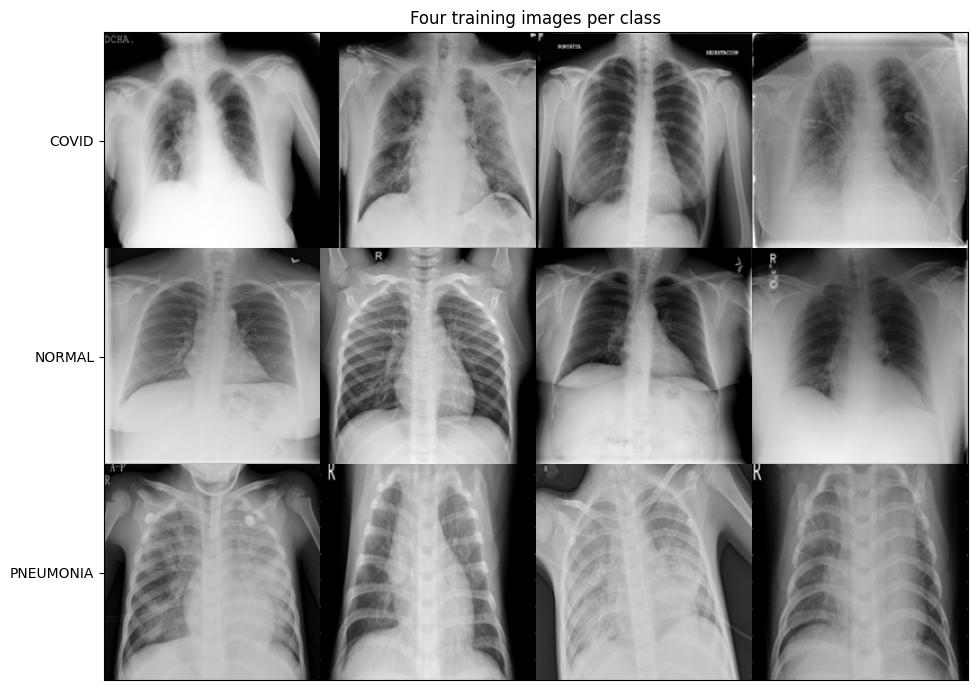

,class,file
0,COVID,COVID-1366.png
1,COVID,COVID-3133.png
2,COVID,COVID-2956.png
3,COVID,COVID-3.png
4,NORMAL,Normal-8877.png
5,NORMAL,Normal-870.png
6,NORMAL,Normal-5525.png
7,NORMAL,Normal-9630.png
8,PNEUMONIA,Viral Pneumonia-209.png
9,PNEUMONIA,Viral Pneumonia-1047.png


In [ ]:
# Count each class in the train, validation and test splits.
split_counts = pd.crosstab(manifest['class'], manifest['split']).reindex(
    index=class_names, columns=['train', 'validation', 'test'])
split_counts['total'] = split_counts.sum(axis=1)
display(split_counts)

# Summarize image dimensions and pixel values within each class and split.
rows = []
for split, images, labels in [('train', X_train, y_train), ('validation', X_val, y_val), ('test', X_test, y_test)]:
    label_ids = np.argmax(np.asarray(labels), axis=1)
    for k, name in enumerate(class_names):
        subset = images[label_ids == k]
        rows.append({'split': split, 'class': name, 'n': len(subset),
                     'height': images.shape[1], 'width': images.shape[2], 'channels': images.shape[3],
                     'mean_intensity': float(np.mean(subset)), 'std_intensity': float(np.std(subset)),
                     'min_intensity': float(np.min(subset)), 'max_intensity': float(np.max(subset))})
        del subset
display(pd.DataFrame(rows).round(4))

# Only training images are used for qualitative exploration.
label_ids = np.argmax(np.asarray(y_train), axis=1)
grid_rows, selected_examples = [], []
for k, name in enumerate(class_names):
    local_ids = np.flatnonzero(label_ids == k)[:4]
    grid_rows.append(np.concatenate([X_train[i] for i in local_ids], axis=1))
    for i in local_ids:
        selected_examples.append({'class': name, 'file': Path(image_filepaths[idx_train[i]]).name})
# Show four training images per class and list their filenames below.
plt.figure(figsize=(10, 7))
plt.imshow(np.concatenate(grid_rows, axis=0))
plt.yticks([(k + 0.5) * IMG_SIZE for k in range(3)], class_names)
plt.xticks([]); plt.title('Four training images per class'); plt.tight_layout(); plt.show()
display(pd.DataFrame(selected_examples))

## **1. Dataset and Exploratory Data Analysis**






The above cell displays 4 labeled sample images from each class, as well as a dataframe displaying the number of images per class in each split, image dimensions, and pixel intensity statistics.

The images have been converted to RGB for the pretrained networks; that does not add information to the original grayscale image. Resizing gives every model the same input dimensions, but can remove fine detail and change aspect ratios.

The grid is useful for checking positioning, contrast, borders and within-class variation. Differences in brightness alone do not identify disease. A classifier might also learn scanner marks or source-specific appearance rather than clinically useful features. The checks here cannot rule that out.

Interpret any differences visible in the grid alongside the actual class statistics, rather than assuming one disease class always have a particular appearance.

In [ ]:
# Compare the original class counts with the balanced project sample.
balance = pd.DataFrame({'Full three-class subset': pd.Series(original_counts),
                        'Used in project': pd.Series({k: n_per_class for k in class_names})})
display(balance)

# Describe the original imbalance using counts, not model predictions.
majority_ratio = max(original_counts.values()) / min(original_counts.values())
normal_share = original_counts['NORMAL'] / sum(original_counts.values())
print("")
display(Markdown(f'The largest class is **{majority_ratio:.2f} times** the smallest. '
                 f'Normal images account for **{normal_share:.1%}** of the three-class subset.'))

,Full three-class subset,Used in project
COVID,3616,1345
NORMAL,10192,1345
PNEUMONIA,1345,1345


The largest class is **7.58 times** the smallest. Normal images account for **67.3%** of the three-class subset.

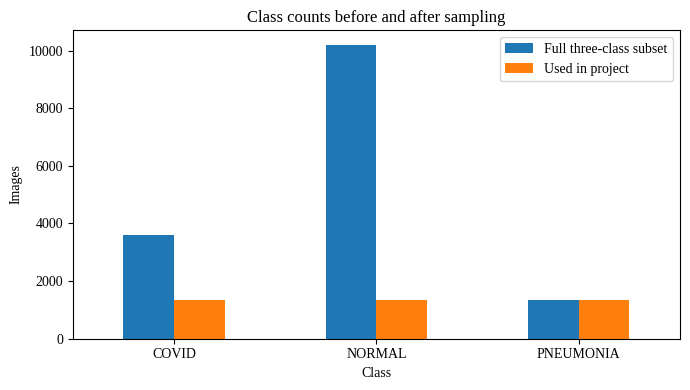

In [ ]:
# Display class counts
with plt.rc_context({'font.family': 'serif',
                     'font.serif': ['Times New Roman', 'Liberation Serif', 'STIXGeneral']}):
    ax = balance.plot.bar(figsize=(7, 4), rot=0)
    ax.set_ylabel('Images'); ax.set_xlabel('Class'); ax.set_title('Class counts before and after sampling')
    plt.tight_layout(); plt.show()

### **Class balance:**

The full dataset is imbalanced, but Section 0 uses the same number of images from each class. Using original_counts, plot the number of images per class in the full dataset next to the number used in this project.

___________________________________


Section 0 uses random undersampling without replacement. It keeps all 1,345 Viral Pneumonia images and samples the same number from each larger class. This reduces training cost and gives equal class frequencies, but discards many available images. It is not oversampling or augmentation. It's important to keep in mind that the balanced test sample does not represent clinical prevalence.

With the full dataset, I would start with class-weighted cross-entropy, calculating weights from the training split only: `n_train / (3 * n_train_class)`. This keeps all real training images while reducing majority-class dominance. I would compare macro-F1 and per-class recall, not just accuracy. Better minority recall is a possibility, not a guaranteed result; majority-class accuracy and calibration could worsen.

### Practical value

A properly validated model could help prioritize radiology review, but this project does not establish clinical usefulness. There is no verified patient-level split, external hospital test set or prospective evaluation. The classifier also has no category for other conditions or unusable images. It should not be used for diagnosis.

## **2. Baseline CNN**

Build and train a basic Convolutional Neural Network (CNN) from scratch. It will be the baseline that you compare every other model with.

Train on X_train and y_train, pass validation_data=(X_val, y_val) to fit, and save the training history so that you can plot it in Section 5.

<br>

___________________________________


The baseline uses three 3 × 3 convolution blocks with 32, 64 and 128 filters. Each has BatchNorm, ReLU and 2 × 2 max pooling. Global average pooling is followed by a 128-unit dense layer, dropout of 0.30 and three-class softmax. Pooling avoids a large flattened fully connected layer.

The loss is categorical cross-entropy. Adam starts at 0.001, with batch size 32 and a maximum of 25 epochs. The learning rate is reduced after two epochs without validation-loss improvement; early stopping has patience four. The best validation-loss weights are restored.

The initial weights are saved before fitting so that the later augmentation experiment can start from the same CNN weights.

In [ ]:
# Train a fresh baseline unless a completed run has already been restored.
if not RESTORED:
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)
    baseline_model, _, baseline_extractor, baseline_head = build_baseline()
    baseline_model.summary()

    # Keep the starting weights for the later augmentation A/B comparison.
    initial_path = RUN_DIR / 'baseline_initial.weights.h5'
    baseline_model.save_weights(initial_path)
    baseline_initial_hash = sha256_file(initial_path)
    # Train from scratch and keep the checkpoint with the lowest validation loss.
    baseline_history, baseline_seconds = fit_stage(baseline_model, 'BaselineCNN', BASELINE_EPOCHS, 1e-3)
else:
    print('Baseline training skipped: using the restored run.')

Model: "baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 192, 192, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_1 (Conv2D)                 │ (None, 192, 192, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_1 (BatchNormalization)       │ (None, 192, 192, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_1 (Activation)             │ (None, 192, 192, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_1 (MaxPooling2D)           │ (None, 96, 96, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 96, 96, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_2 (BatchNormalization)       │ (None, 96, 96, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_2 (Activation)             │ (None, 96, 96, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_2 (MaxPooling2D)           │ (None, 48, 48, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_3 (Conv2D)                 │ (None, 48, 48, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_3 (BatchNormalization)       │ (None, 48, 48, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_3 (Activation)             │ (None, 48, 48, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_3 (MaxPooling2D)           │ (None, 24, 24, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classification_head             │ (None, 3)              │        16,899 │
│ (Functional)                    │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,819 (432.89 KB)

 Trainable params: 110,371 (431.14 KB)

 Non-trainable params: 448 (1.75 KB)

Epoch 1/25
81/81 - 17s - 214ms/step - accuracy: 0.6646 - loss: 0.7364 - val_accuracy: 0.3344 - val_loss: 1.3565 - learning_rate: 0.0010
Epoch 2/25
81/81 - 7s - 87ms/step - accuracy: 0.7351 - loss: 0.6030 - val_accuracy: 0.3344 - val_loss: 1.6947 - learning_rate: 0.0010
Epoch 3/25
81/81 - 7s - 89ms/step - accuracy: 0.7595 - loss: 0.5417 - val_accuracy: 0.3344 - val_loss: 1.6574 - learning_rate: 0.0010
Epoch 4/25
81/81 - 7s - 87ms/step - accuracy: 0.8040 - loss: 0.4725 - val_accuracy: 0.3576 - val_loss: 1.7658 - learning_rate: 5.0000e-04
Epoch 5/25
81/81 - 7s - 91ms/step - accuracy: 0.8246 - loss: 0.4294 - val_accuracy: 0.4319 - val_loss: 1.6116 - learning_rate: 5.0000e-04


### **Training, validation and test evaluation baseline CNN**

These scores use inference mode. Training accuracy here can differ from the training history because dropout and BatchNorm behave differently during fitting.

In [ ]:
# Save baseline predictions and metrics, then release the model from memory.
if not RESTORED:
    record_model(baseline_model, 'BaselineCNN', 'BaselineCNN',
                 [{'name': 'scratch', 'history': baseline_history, 'learning_rate': 1e-3}],
                 baseline_seconds, initial_hash=baseline_initial_hash)
    del baseline_model, baseline_extractor, baseline_head
    keras.backend.clear_session(); gc.collect()

# For a restored run, display the saved scores without training again.
else:
    display(pd.DataFrame(records['BaselineCNN']['metrics']).T.round(4))

,loss,accuracy,macro_f1,covid_recall,macro_auc_ovr
train,1.3572,0.3331,0.1666,1.0,0.6244
validation,1.3565,0.3344,0.1671,1.0,0.6104
test,1.3545,0.3333,0.1667,1.0,0.6324


## 3. ResNet50 Transfer Learning with ResNet

1. Load ResNet50 without its top classification layer, freeze its layers, and add your own classification head. Train only the new head.
2. **Fine-tune** the model: unfreeze some of the top ResNet layers and continue training with a low learning rate.
3. Compare its performance with the baseline CNN.

---------------------

ResNet50 starts with ImageNet weights and no original classifier. Inputs are converted from [0, 1] to [0, 255] before ResNet preprocessing. The new head has the same design as the other transfer models.

First, train only the head for up to 10 epochs at 0.001. Then unfreeze the `conv5_` block and train for up to 10 more epochs at 0.00001. BatchNorm remains frozen and the backbone is called with `training=False`. The optimizer is re-created after changing trainability. Both stages are saved so fine-tuning cannot hide a better frozen result.

In [ ]:
# 1. Train the ResNet classification head while the ImageNet backbone stays frozen.
if not RESTORED:
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)
    resnet_model, resnet_base, resnet_extractor, resnet_head = build_transfer('ResNet50')
    resnet_model.summary()
    resnet_head_history, resnet_head_seconds = fit_stage(
        resnet_model, 'ResNet50_frozen', HEAD_EPOCHS, 1e-3)
    # Save this stage separately before fine-tuning changes the weights.
    record_model(resnet_model, 'ResNet50_frozen', 'ResNet50',
                 [{'name': 'head', 'history': resnet_head_history, 'learning_rate': 1e-3}],
                 resnet_head_seconds)
else:
    display(pd.DataFrame(records['ResNet50_frozen']['metrics']).T.round(4))

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "ResNet50"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 192, 192, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ input_preprocessing             │ (None, 192, 192, 3)    │             0 │
│ (ApplicationPreprocessing)      │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 6, 6, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classification_head             │ (None, 3)              │       262,659 │
│ (Functional)                    │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,850,371 (90.98 MB)

 Trainable params: 262,659 (1.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

Epoch 1/10
81/81 - 22s - 268ms/step - accuracy: 0.8172 - loss: 0.4397 - val_accuracy: 0.8653 - val_loss: 0.3691 - learning_rate: 0.0010
Epoch 2/10
81/81 - 11s - 132ms/step - accuracy: 0.8950 - loss: 0.2587 - val_accuracy: 0.9288 - val_loss: 0.1979 - learning_rate: 0.0010
Epoch 3/10
81/81 - 11s - 140ms/step - accuracy: 0.9276 - loss: 0.1809 - val_accuracy: 0.9365 - val_loss: 0.1802 - learning_rate: 0.0010
Epoch 4/10
81/81 - 10s - 122ms/step - accuracy: 0.9202 - loss: 0.1971 - val_accuracy: 0.9334 - val_loss: 0.1821 - learning_rate: 0.0010
Epoch 5/10
81/81 - 10s - 122ms/step - accuracy: 0.9427 - loss: 0.1501 - val_accuracy: 0.9180 - val_loss: 0.1816 - learning_rate: 0.0010
Epoch 6/10
81/81 - 12s - 149ms/step - accuracy: 0.9706 - loss: 0.0839 - val_accuracy: 0.9427 - val_loss: 0.1409 - learning_rate: 5.0000e-04
Epoch 7/10
81/81 - 10s - 123ms/step - accuracy: 0.9737 - loss: 0.0748 - val_accuracy: 0.9536 - val_loss: 0.1644 - learning_rate: 5.0000e-04
Epoch 8/10
81/81 - 10s - 126ms/step - ac

,loss,accuracy,macro_f1,covid_recall,macro_auc_ovr
train,0.0340,0.9884,0.9884,0.9744,0.9998
validation,0.1325,0.9598,0.9595,0.9630,0.9947
test,0.1432,0.9430,0.9428,0.8996,0.9935


### Fine-tune the model: unfreeze some of the top ResNet layers and continue training with a low learning rate.

In [ ]:
# 2. Fine-tune the upper ResNet block from the frozen-stage checkpoint.
if not RESTORED:
    unfreeze_top_block(resnet_base, 'ResNet50') # Unfreeze top resnet layers
    resnet_fine_history, resnet_fine_seconds = fit_stage(
        resnet_model, 'ResNet50_finetuned', FINETUNE_EPOCHS, 1e-5)

    # Store both histories and the combined fit time for the full ResNet run.
    record_model(resnet_model, 'ResNet50_finetuned', 'ResNet50',
                 [{'name': 'head', 'history': resnet_head_history, 'learning_rate': 1e-3},
                  {'name': 'fine-tune', 'history': resnet_fine_history, 'learning_rate': 1e-5}],
                 resnet_head_seconds + resnet_fine_seconds)
    del resnet_model, resnet_base, resnet_extractor, resnet_head
    keras.backend.clear_session(); gc.collect()
else:
    display(pd.DataFrame(records['ResNet50_finetuned']['metrics']).T.round(4))

Epoch 1/10
81/81 - 26s - 327ms/step - accuracy: 0.9806 - loss: 0.0536 - val_accuracy: 0.9582 - val_loss: 0.1366 - learning_rate: 1.0000e-05
Epoch 2/10
81/81 - 13s - 164ms/step - accuracy: 0.9942 - loss: 0.0171 - val_accuracy: 0.9536 - val_loss: 0.1686 - learning_rate: 1.0000e-05
Epoch 3/10
81/81 - 13s - 164ms/step - accuracy: 0.9977 - loss: 0.0085 - val_accuracy: 0.9505 - val_loss: 0.1920 - learning_rate: 1.0000e-05
Epoch 4/10
81/81 - 13s - 165ms/step - accuracy: 0.9988 - loss: 0.0048 - val_accuracy: 0.9613 - val_loss: 0.1866 - learning_rate: 5.0000e-06
Epoch 5/10
81/81 - 13s - 163ms/step - accuracy: 0.9992 - loss: 0.0040 - val_accuracy: 0.9628 - val_loss: 0.1804 - learning_rate: 5.0000e-06


,loss,accuracy,macro_f1,covid_recall,macro_auc_ovr
train,0.0132,0.9965,0.9965,0.9930,1.0000
validation,0.1366,0.9582,0.9581,0.9583,0.9949
test,0.1310,0.9529,0.9528,0.9257,0.9949


### Comparison of each resnet model with the baseline CNN

In [ ]:
# 3. Evaluate the baseline
# Display the baseline, frozen ResNet and fine-tuned ResNet side by side.
compare_resnet()

,validation_macro_f1,test_accuracy,test_macro_f1,fit_minutes
model,,,,
BaselineCNN,0.1671,0.3333,0.1667,0.8574
ResNet50_frozen,0.9595,0.9430,0.9428,2.0420
ResNet50_finetuned,0.9581,0.9529,0.9528,3.4147


ResNet50_finetuned versus BaselineCNN: test macro-F1 differs by +0.786. Validation macro-F1 is 0.958 versus 0.167.

ResNet50_finetuned versus ResNet50_frozen: test macro-F1 differs by +0.010. Validation macro-F1 is 0.958 versus 0.960.

Pretraining supplies an initial set of visual features instead of learning every filter from this small training set. Freezing limits the number of fitted parameters; fine-tuning lets the upper block adapt while earlier filters stay fixed.

Fine tuning allows the model to adjust the imagenet features to perform more accurately on specific images, in this case Xrays, which are less represented within the imagenet training set itself. This adjustment to the model also increased training time.

The table displays how each modification affected scores for each run. A lower training loss alone is not enough: check validation scores and the curves in Section 5. Fewer epochs do not necessarily mean less time, because ResNet is larger than the baseline. The comparison also changes architecture and training schedule, so it does not isolate pretraining by itself.

## 4. Additional architectures

All three models use the same data, split, head, seed, batch size, callbacks and two-stage epoch budget. The backbone, its required preprocessing and the upper block chosen for fine-tuning differ. Equal epochs do not mean equal compute; fit time and parameter counts are saved separately.

### MobileNetV2

This is the smaller model in the comparison. It uses depthwise operations and inverted residual blocks. Its input preprocessing maps pixels to [-1, 1]. Fine-tuning covers blocks 13–16 and `Conv_1`, excluding BatchNorm.

In [ ]:
# Run both MobileNetV2 stages, or display the scores from the restored run.
if not RESTORED:
    run_additional('MobileNetV2')
else:
    display(pd.DataFrame(records['MobileNetV2']['metrics']).T.round(4))

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 192, 192, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ input_preprocessing             │ (None, 192, 192, 3)    │             0 │
│ (ApplicationPreprocessing)      │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_192            │ (None, 6, 6, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classification_head             │ (None, 3)              │       164,355 │
│ (Functional)                    │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,339 (9.24 MB)

 Trainable params: 164,355 (642.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/10
81/81 - 14s - 170ms/step - accuracy: 0.8362 - loss: 0.3927 - val_accuracy: 0.9025 - val_loss: 0.2460 - learning_rate: 0.0010
Epoch 2/10
81/81 - 5s - 62ms/step - accuracy: 0.9109 - loss: 0.2179 - val_accuracy: 0.9226 - val_loss: 0.2284 - learning_rate: 0.0010
Epoch 3/10
81/81 - 5s - 64ms/step - accuracy: 0.9392 - loss: 0.1579 - val_accuracy: 0.9303 - val_loss: 0.2181 - learning_rate: 0.0010
Epoch 4/10
81/81 - 5s - 61ms/step - accuracy: 0.9500 - loss: 0.1308 - val_accuracy: 0.9272 - val_loss: 0.2327 - learning_rate: 0.0010
Epoch 5/10
81/81 - 5s - 68ms/step - accuracy: 0.9663 - loss: 0.1000 - val_accuracy: 0.9412 - val_loss: 0.1870 - learning_rate: 0.0010
Epoch 6/10
81/81 - 6s - 69ms/step - accuracy: 0.9741 - loss: 0.0782 - val_accuracy: 0.9365 - val_loss: 0.1787 - learning_rate: 0.0010
Epoch 7/10
81/81 - 4s - 53ms/step - accuracy: 0.9779 - loss: 0.0695 - val_accuracy: 0.9303 - val_loss: 0.2018 - learning_rate: 0.0010
Epoch 8/10
81/81 - 4s - 53ms/step - accuracy: 0.9779 - loss:

,loss,accuracy,macro_f1,covid_recall,macro_auc_ovr
train,0.0156,0.9938,0.9938,0.9930,1.000
validation,0.1602,0.9520,0.9521,0.9398,0.995
test,0.2038,0.9418,0.9422,0.9145,0.994


### DenseNet121

DenseNet connects later layers to earlier feature maps, providing a contrast to ResNet's additive shortcuts. Its own ImageNet normalization is applied internally. Fine-tuning is limited to the last dense block, excluding BatchNorm.

In [ ]:
# Run both DenseNet121 stages, or display the scores from the restored run.
if not RESTORED:
    run_additional('DenseNet121')
else:
    display(pd.DataFrame(records['DenseNet121']['metrics']).T.round(4))

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "DenseNet121"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 192, 192, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ input_preprocessing             │ (None, 192, 192, 3)    │             0 │
│ (ApplicationPreprocessing)      │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet121 (Functional)        │ (None, 6, 6, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classification_head             │ (None, 3)              │       131,587 │
│ (Functional)                    │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,169,091 (27.35 MB)

 Trainable params: 131,587 (514.01 KB)

 Non-trainable params: 7,037,504 (26.85 MB)

Epoch 1/10
81/81 - 32s - 397ms/step - accuracy: 0.7835 - loss: 0.5190 - val_accuracy: 0.8932 - val_loss: 0.2824 - learning_rate: 0.0010
Epoch 2/10
81/81 - 14s - 169ms/step - accuracy: 0.8641 - loss: 0.3242 - val_accuracy: 0.9009 - val_loss: 0.2655 - learning_rate: 0.0010
Epoch 3/10
81/81 - 13s - 161ms/step - accuracy: 0.8900 - loss: 0.2597 - val_accuracy: 0.9164 - val_loss: 0.2262 - learning_rate: 0.0010
Epoch 4/10
81/81 - 13s - 165ms/step - accuracy: 0.9047 - loss: 0.2389 - val_accuracy: 0.9195 - val_loss: 0.2198 - learning_rate: 0.0010
Epoch 5/10
81/81 - 11s - 139ms/step - accuracy: 0.9148 - loss: 0.2052 - val_accuracy: 0.9102 - val_loss: 0.2490 - learning_rate: 0.0010
Epoch 6/10
81/81 - 11s - 137ms/step - accuracy: 0.9245 - loss: 0.1887 - val_accuracy: 0.9195 - val_loss: 0.2328 - learning_rate: 0.0010
Epoch 7/10
81/81 - 13s - 165ms/step - accuracy: 0.9380 - loss: 0.1587 - val_accuracy: 0.9272 - val_loss: 0.1923 - learning_rate: 5.0000e-04
Epoch 8/10
81/81 - 14s - 169ms/step - accura

,loss,accuracy,macro_f1,covid_recall,macro_auc_ovr
train,0.0251,0.9957,0.9957,0.9884,1.0000
validation,0.1421,0.9381,0.9378,0.9074,0.9939
test,0.1418,0.9455,0.9456,0.9071,0.9936


### EfficientNetB0

EfficientNetB0 provides another parameter and compute trade-off. It already contains input rescaling, so the stored arrays are multiplied by 255 before entering it, without another external normalization. Fine-tuning covers the last MBConv block and top convolution, excluding BatchNorm.

In [ ]:
# Run both EfficientNetB0 stages, or display the scores from the restored run.
if not RESTORED:
    run_additional('EfficientNetB0')
else:
    display(pd.DataFrame(records['EfficientNetB0']['metrics']).T.round(4))

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "EfficientNetB0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 192, 192, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ input_preprocessing             │ (None, 192, 192, 3)    │             0 │
│ (ApplicationPreprocessing)      │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 6, 6, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classification_head             │ (None, 3)              │       164,355 │
│ (Functional)                    │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,213,926 (16.07 MB)

 Trainable params: 164,355 (642.01 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

Epoch 1/10
81/81 - 21s - 258ms/step - accuracy: 0.8226 - loss: 0.4133 - val_accuracy: 0.8854 - val_loss: 0.2631 - learning_rate: 0.0010
Epoch 2/10
81/81 - 7s - 85ms/step - accuracy: 0.8954 - loss: 0.2580 - val_accuracy: 0.9180 - val_loss: 0.2040 - learning_rate: 0.0010
Epoch 3/10
81/81 - 7s - 81ms/step - accuracy: 0.9152 - loss: 0.2180 - val_accuracy: 0.9164 - val_loss: 0.1997 - learning_rate: 0.0010
Epoch 4/10
81/81 - 6s - 78ms/step - accuracy: 0.9249 - loss: 0.1867 - val_accuracy: 0.9133 - val_loss: 0.2226 - learning_rate: 0.0010
Epoch 5/10
81/81 - 6s - 71ms/step - accuracy: 0.9357 - loss: 0.1651 - val_accuracy: 0.9056 - val_loss: 0.2546 - learning_rate: 0.0010
Epoch 6/10
81/81 - 9s - 107ms/step - accuracy: 0.9411 - loss: 0.1540 - val_accuracy: 0.9396 - val_loss: 0.1558 - learning_rate: 5.0000e-04
Epoch 7/10
81/81 - 6s - 70ms/step - accuracy: 0.9489 - loss: 0.1248 - val_accuracy: 0.9412 - val_loss: 0.1587 - learning_rate: 5.0000e-04
Epoch 8/10
81/81 - 7s - 90ms/step - accuracy: 0.954

,loss,accuracy,macro_f1,covid_recall,macro_auc_ovr
train,0.0517,0.9861,0.9860,0.9849,0.9994
validation,0.1397,0.9489,0.9486,0.9444,0.9934
test,0.1174,0.9492,0.9492,0.9294,0.9955


### Files for the handoff

This check runs only after all six records exist. It rechecks predictions against the recorded metrics and saves a completion file for Sections 0–4. It does not say Sections 5–7 or the final submission are finished.

In [ ]:
# Check all six records before marking Sections 0–4 as complete.
expected_models = {'BaselineCNN', 'ResNet50_frozen', 'ResNet50_finetuned',
                   'MobileNetV2', 'DenseNet121', 'EfficientNetB0'}
if set(records) != expected_models:
    raise RuntimeError('Finish all models in Sections 2–4 before creating the handoff.')
# Check the saved files, recompute metrics and confirm prediction row order.
for name, record in records.items():
    assert record['config_hash'] == CONFIG_HASH and record['data_hash'] == DATA_HASH
    assert sha256_file(RUN_DIR / record['model_file']) == record['model_sha256']
    for split, labels, ids in [('train', y_train, idx_train),
                                ('validation', y_val, idx_val),
                                ('test', y_test, idx_test)]:
        actual = metric_record(labels, load_predictions(name, split))
        assert all(np.isclose(actual[k], record['metrics'][split][k],
                              rtol=0, atol=1e-10) for k in actual)
        with np.load(RUN_DIR / record['predictions'], allow_pickle=False) as arrays:
            np.testing.assert_array_equal(arrays[split + '_ids'], ids)
            np.testing.assert_array_equal(arrays[split + '_labels'],
                                          np.asarray(labels).argmax(axis=1))
# Make sure the augmentation comparison will use the original starting weights.
assert sha256_file(initial_path) == records['BaselineCNN']['initial_weights_sha256']
save_state()
# Write the completion record only after every check above passes.
completion = {
    'scope': 'sections_0_4', 'status': 'complete',
    'data_hash': DATA_HASH, 'config_hash': CONFIG_HASH,
    'results_sha256': sha256_file(RUN_DIR / 'results.json'),
    'manifest_sha256': sha256_file(RUN_DIR / 'split_manifest.csv'),
    'initial_weights_sha256': sha256_file(initial_path),
    'models': sorted(records),
}
(RUN_DIR / 'completed_0_4.json').write_text(json.dumps(completion, indent=2))
print('Sections 0–4 results saved to:', RUN_DIR)
print('Download this notebook with its outputs and keep the run folder for Sav.')

Sections 0–4 results saved to: /content/drive/MyDrive/QMSS5074_Project2/run_20261116T234743_556957Z
Download this notebook with its outputs and keep the run folder for Sav.


## 5. Performance comparison

Use the results from Sections 2–4. `records` contains the metrics, training histories, learning rates, fit times and parameter counts; `load_predictions(name, split)` reads aligned probabilities.


In [ ]:
# Section 5: compare all six models on the same test set.
model_order = ['BaselineCNN', 'ResNet50_frozen', 'ResNet50_finetuned',
               'MobileNetV2', 'DenseNet121', 'EfficientNetB0']

# --- Check that every model was scored on the same test set -----------------
# Every model's test predictions must cover the same images and classes.
test_shapes = {name: np.asarray(load_predictions(name, 'test')).shape
               for name in model_order}
assert len(set(test_shapes.values())) == 1, f'Test sets differ: {test_shapes}'
n_test, n_classes = next(iter(test_shapes.values()))
print(f'All {len(model_order)} models scored on the same test set: '
      f'{n_test} images, {n_classes} classes.\n')

# --- Learning rate(s) for each model, read from its saved training stages ---
def learning_rates(r):
    """Return e.g. 'frozen: 0.001 → finetune: 1e-05' from the saved stage list."""
    for value in r.values():
        if (isinstance(value, list) and value and isinstance(value[0], dict)
                and 'learning_rate' in value[0]):
            return ' → '.join(f"{s.get('name', 'stage')}: {s['learning_rate']:g}"
                              for s in value)
    return 'not recorded'

# --- One row per model, built from the saved records ------------------------
rows = []
for name in model_order:
    r = records[name]
    test = r['metrics']['test']
    rows.append({
        'model': name,
        'val_macro_f1': r['metrics']['validation']['macro_f1'],
        'test_loss': test['loss'],
        'test_accuracy': test['accuracy'],
        'test_macro_f1': test['macro_f1'],
        'test_covid_recall': test['covid_recall'],
        'test_macro_auc': test['macro_auc_ovr'],
        'learning_rate': learning_rates(r),       # text, so 1e-05 isn't rounded to 0
        'parameters_M': r['parameters'] / 1e6,
        'fit_minutes': r['fit_seconds'] / 60,
    })
comparison = pd.DataFrame(rows).set_index('model')

# --- Two separate rankings ---------------------------------------------------
# Validation rank: used to CHOOSE the model (decided without looking at test scores).
comparison.insert(0, 'val_rank',
                  comparison['val_macro_f1'].rank(ascending=False, method='min').astype(int))
# Test rank: DESCRIPTIVE only; reports how the models did, not used to choose.
comparison.insert(1, 'test_rank',
                  comparison['test_macro_f1'].rank(ascending=False, method='min').astype(int))
comparison = comparison.sort_values('test_rank')

chosen = comparison['val_macro_f1'].idxmax()      # validation-based model choice
top_test = comparison['test_macro_f1'].idxmax()   # highest test score (descriptive)

# --- Display: shade the best value in each score column ---------------------
best_high = ['val_macro_f1', 'test_accuracy', 'test_macro_f1',
             'test_covid_recall', 'test_macro_auc']
display(comparison.style
        .highlight_max(subset=best_high, color='#cdeccd')
        .highlight_min(subset=['test_loss'], color='#cdeccd')
        .format(precision=4))

# --- Summary that keeps the two rankings separate ---------------------------
print(f'Model selected by validation macro-F1: {chosen} '
      f"(val macro-F1 = {comparison.loc[chosen, 'val_macro_f1']:.4f})")
print(f'Highest test macro-F1 (descriptive only): {top_test} '
      f"(test macro-F1 = {comparison.loc[top_test, 'test_macro_f1']:.4f})")
if chosen == top_test:
    print('The validation choice also has the highest test macro-F1.')
else:
    print(f'The rankings differ: {top_test} scored highest on test, but the choice '
          f'stays {chosen} because selection was made on validation, not test, data.')

All 6 models scored on the same test set: 807 images, 3 classes.



,val_rank,test_rank,val_macro_f1,test_loss,test_accuracy,test_macro_f1,test_covid_recall,test_macro_auc,learning_rate,parameters_M,fit_minutes
model,,,,,,,,,,,
ResNet50_finetuned,2,1,0.9581,0.1310,0.9529,0.9528,0.9257,0.9949,head: 0.001 → fine-tune: 1e-05,23.8504,3.4147
EfficientNetB0,4,2,0.9486,0.1174,0.9492,0.9492,0.9294,0.9955,head: 0.001 → fine-tune: 1e-05,4.2139,2.2387
DenseNet121,5,3,0.9378,0.1418,0.9455,0.9456,0.9071,0.9936,head: 0.001 → fine-tune: 1e-05,7.1691,5.1225
ResNet50_frozen,1,4,0.9595,0.1432,0.9430,0.9428,0.8996,0.9935,head: 0.001,23.8504,2.0420
MobileNetV2,3,5,0.9521,0.2038,0.9418,0.9422,0.9145,0.9940,head: 0.001 → fine-tune: 1e-05,2.4223,2.0484
BaselineCNN,6,6,0.1671,1.3545,0.3333,0.1667,1.0000,0.6324,scratch: 0.001,0.1108,0.8574


Model selected by validation macro-F1: ResNet50_frozen (val macro-F1 = 0.9595)
Highest test macro-F1 (descriptive only): ResNet50_finetuned (test macro-F1 = 0.9528)
The rankings differ: ResNet50_finetuned scored highest on test, but the choice stays ResNet50_frozen because selection was made on validation, not test, data.


The top performing model was selected using the validation macro F1 score, because it is appropriate for datasets where every class is equally important. ResNet50_frozen achieved the highest validation macro F1 with a score of 0.9595. Test scores are reported for description only. All models built with transfer learning performed strongly on the test set, with the lowest test macro F1 score being 0.9422, associated with the MobileNetV2 model. ResNet50_finetuned had the highest test macro F1 score (0.9528), but since this was not used for selection, it is a descriptive result rather than the basis for choosing a model. The baseline CNN performed poorly, with a test macro F1 score of 0.1667. It is notable that despite such a low test macro F1 score, the baseline CNN achieved a recall of 1.0 for COVID images, meaning it identified every COVID X-ray. This is something that will be discussed within the summary section.




### **Hyperparameters and training curves**


In [ ]:
# Hyperparameter summary: one row per model and training phase.
def find(keys, *sources):
    """Return the first value found for any of `keys` in the given dictionaries."""
    for src in sources:
        if isinstance(src, dict):
            for k in keys:
                if src.get(k) is not None:
                    return src[k]
    return None

config = globals().get('EXPERIMENT_CONFIG', {})

# Epoch budget for each type of training phase.
BUDGET_KEYS = {'scratch': 'baseline_epochs',
               'head': 'head_epochs',
               'fine-tune': 'finetune_epochs'}

rows = []
for name in model_order:
    r = records[name]
    for phase in r['phases']:
        hist = phase['history']
        hist = getattr(hist, 'history', hist)           # Keras History object or plain dict
        epochs_run = len(hist['loss'])
        phase_name = phase.get('name', 'training')
        budget = config.get(BUDGET_KEYS.get(phase_name))

        # Learning rate at the end, if a scheduler changed it during training.
        lr_log = find(['learning_rate', 'lr'], hist)
        final_lr = lr_log[-1] if isinstance(lr_log, (list, tuple)) and lr_log else None

        rows.append({
            'model': name,
            'phase': phase_name,
            'optimizer': find(['optimizer', 'optimizer_name'], phase, r, config),
            'start_lr': f"{phase['learning_rate']:g}",
            'final_lr': f'{final_lr:g}' if final_lr is not None else '–',
            'batch_size': find(['batch_size'], phase, r, config),
            'epoch_budget': budget,
            'patience': config.get('patience'),
            'epochs_run': epochs_run,
            'stopped_early': (epochs_run < budget) if budget else None,
        })

hyperparams = pd.DataFrame(rows).set_index(['model', 'phase'])
display(hyperparams)

missing = [c for c in ['optimizer', 'batch_size', 'epoch_budget']
           if hyperparams[c].isna().any()]
if missing:
    print(f'Not found automatically: {missing}.')

optimizer start_lr final_lr  batch_size  \
model              phase                                               
BaselineCNN        scratch        Adam    0.001   0.0005          32   
ResNet50_frozen    head           Adam    0.001  0.00025          32   
ResNet50_finetuned head           Adam    0.001  0.00025          32   
                   fine-tune      Adam    1e-05    5e-06          32   
MobileNetV2        head           Adam    0.001   0.0005          32   
                   fine-tune      Adam    1e-05    5e-06          32   
DenseNet121        head           Adam    0.001   0.0005          32   
                   fine-tune      Adam    1e-05  2.5e-06          32   
EfficientNetB0     head           Adam    0.001   0.0005          32   
                   fine-tune      Adam    1e-05    5e-06          32   

                              epoch_budget  patience  epochs_run  \
model              phase                                           
BaselineCNN        scratch              25         4           5   
ResNet50_frozen    head                 10         4          10   
ResNet50_finetuned head                 10         4          10   
                   fine-tune            10         4           5   
MobileNetV2        head                 10         4          10   
                   fine-tune            10         4           9   
DenseNet121        head                 10         4          10   
                   fine-tune            10         4          10   
EfficientNetB0     head                 10         4          10   
                   fine-tune            10         4           5   

                              stopped_early  
model              phase                     
BaselineCNN        scratch             True  
ResNet50_frozen    head               False  
ResNet50_finetuned head               False  
                   fine-tune           True  
MobileNetV2        head               False  
                   fine-tune           True  
DenseNet121        head               False  
                   fine-tune          False  
EfficientNetB0     head               False  
                   fine-tune           True

Above is a summary table including each model's optimizer type, learning rates, batch size, epoch budget, actual epochs (epoch run), and whether or not the model stopped early (true = stopped early, otherwise false)

### Training and validation loss by model

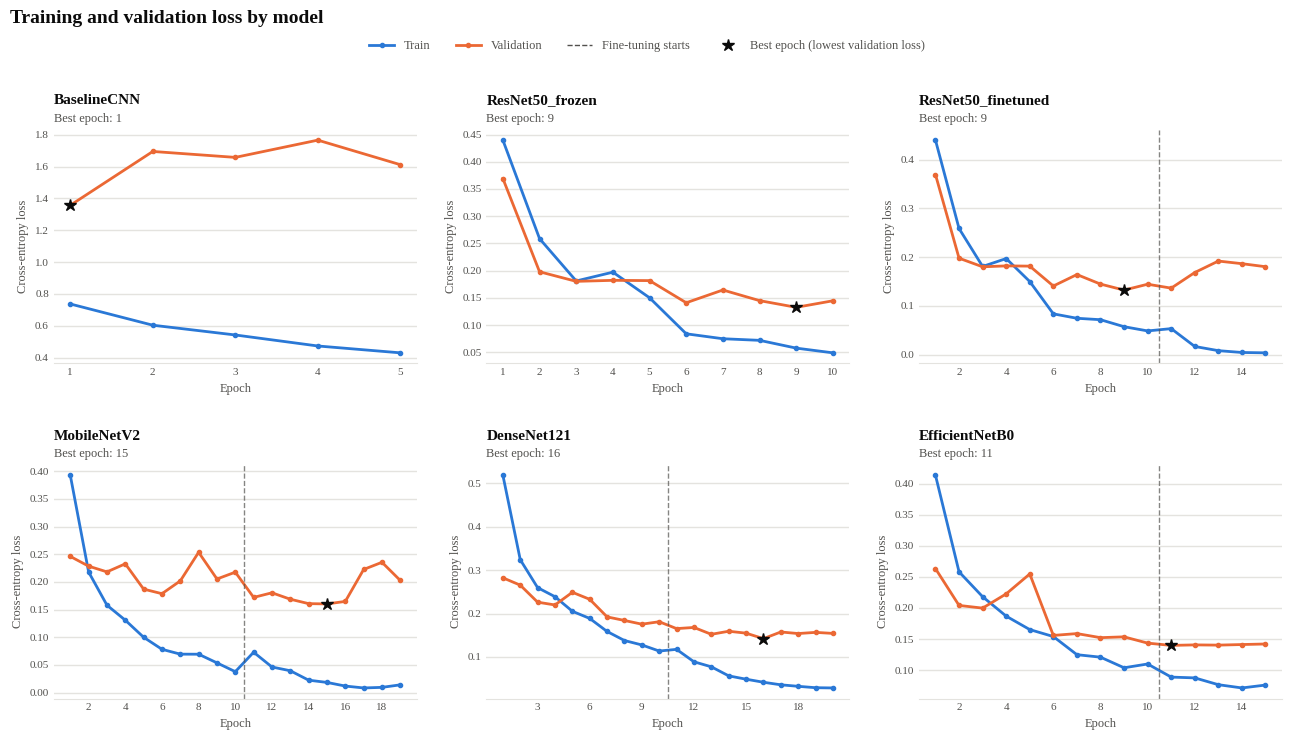

In [ ]:
# Display training and validation loss by model
from matplotlib.ticker import MaxNLocator
from matplotlib.lines import Line2D

# Times New Roman, with close look-alikes as fallbacks if it isn't installed.
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Times New Roman', 'Liberation Serif', 'STIXGeneral', 'DejaVu Serif']

# Shared styling for every panel.
TRAIN_COLOR, VAL_COLOR = '#2a78d6', '#eb6834'      # blue = train, orange = validation
INK, MUTED, GRID = '#0b0b0b', '#52514e', '#e4e3df'

# Join a model's training phases into one continuous history.
# Returns the joined history and the epoch(s) where a new phase starts.
def joined_history(name):
    joined = {k: [] for k in ['loss', 'accuracy', 'val_loss', 'val_accuracy']}
    boundaries = []
    for i, phase in enumerate(records[name]['phases']):
        if i > 0:
            boundaries.append(len(joined['loss']))   # epochs completed before this phase
        for k in joined:
            joined[k].extend(phase['history'][k])
    return joined, boundaries

# Plot one metric as a 2 x 3 grid with one panel per model.
def plot_training_curves(metric, label):
    fig, axes = plt.subplots(2, 3, figsize=(13, 7.5))
    for ax, name in zip(axes.flat, model_order):
        h, boundaries = joined_history(name)
        best_epoch = int(np.argmin(h['val_loss'])) + 1   # lowest validation loss, all phases
        epochs = np.arange(1, len(h[metric]) + 1)

        ax.plot(epochs, h[metric], color=TRAIN_COLOR, linewidth=2,
                marker='o', markersize=3)
        ax.plot(epochs, h['val_' + metric], color=VAL_COLOR, linewidth=2,
                marker='o', markersize=3)
        for b in boundaries:
            ax.axvline(b + 0.5, color=MUTED, linewidth=1, linestyle='--', alpha=0.7)
        # Mark the best epoch on the validation curve.
        ax.plot(best_epoch, h['val_' + metric][best_epoch - 1], marker='*', markersize=9,
                color=INK, linestyle='none', zorder=5)

        # Panel text and axes: model name, best epoch, light grid, no box.
        ax.set_title(name, loc='left', fontsize=11, fontweight='bold', color=INK, pad=18)
        ax.text(0, 1.02, f'Best epoch: {best_epoch}', transform=ax.transAxes,
                fontsize=9, color=MUTED, va='bottom')
        ax.set_xlabel('Epoch', fontsize=9, color=MUTED)
        ax.set_ylabel(label, fontsize=9, color=MUTED)
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))   # whole-number epochs
        ax.tick_params(colors=MUTED, labelsize=8, length=0)
        ax.grid(axis='y', color=GRID, linewidth=1)
        ax.set_axisbelow(True)
        for side in ['top', 'right', 'left']:
            ax.spines[side].set_visible(False)
        ax.spines['bottom'].set_color(GRID)

    # One shared legend for the whole figure instead of one per panel.
    handles = [Line2D([], [], color=TRAIN_COLOR, linewidth=2, marker='o', markersize=3),
               Line2D([], [], color=VAL_COLOR, linewidth=2, marker='o', markersize=3),
               Line2D([], [], color=MUTED, linewidth=1, linestyle='--'),
               Line2D([], [], color=INK, marker='*', markersize=9, linestyle='none')]
    fig.legend(handles, ['Train', 'Validation', 'Fine-tuning starts',
                         'Best epoch (lowest validation loss)'],
               loc='upper center', bbox_to_anchor=(0.5, 0.955), ncol=4,
               frameon=False, fontsize=9, labelcolor=MUTED)
    fig.suptitle(f'Training and validation {metric} by model', x=0.01, ha='left',
                 fontsize=14, fontweight='bold', color=INK)
    fig.tight_layout(rect=[0, 0, 1, 0.93], h_pad=2.5, w_pad=2)
    plt.show()

plot_training_curves('loss', 'Cross-entropy loss')

### Training and validation accuracy by model

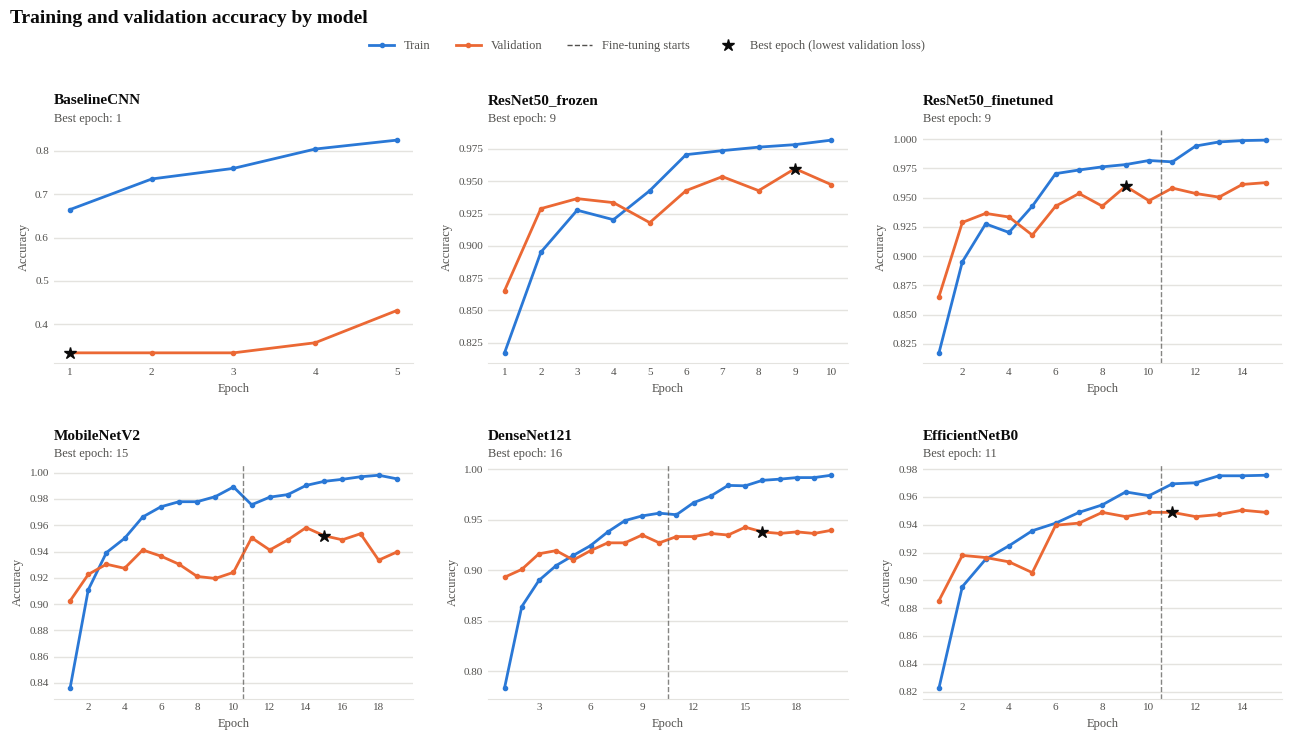

In [ ]:
# Display accuracy training and validation by model
plot_training_curves('accuracy', 'Accuracy')

## 6. Augmentation

Re-train at least one of your models using data augmentation (e.g., flipping, rotation, zoom, cropping, contrast changes), and compare its performance with the same model trained without augmentation.

Tip: Keras augmentation layers such as layers.RandomFlip, layers.RandomRotation, layers.RandomZoom, and layers.RandomContrast can be added at the start of a model. They only change images during training. Think about which augmentations make sense for chest X-rays.


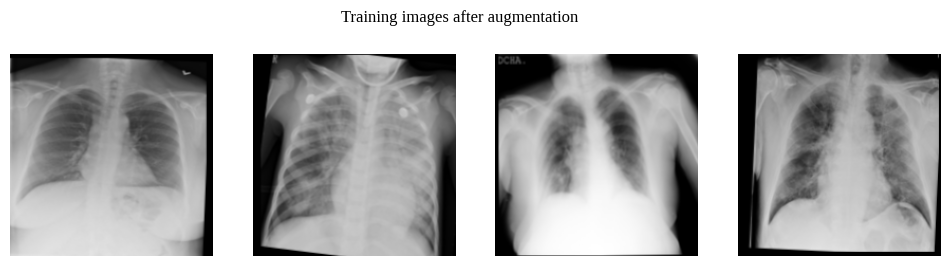

Epoch 1/25
81/81 - 12s - 152ms/step - accuracy: 0.6158 - loss: 0.8337 - val_accuracy: 0.3344 - val_loss: 1.3642 - learning_rate: 0.0010
Epoch 2/25
81/81 - 8s - 94ms/step - accuracy: 0.6967 - loss: 0.6893 - val_accuracy: 0.3344 - val_loss: 1.4819 - learning_rate: 0.0010
Epoch 3/25
81/81 - 8s - 102ms/step - accuracy: 0.7293 - loss: 0.6211 - val_accuracy: 0.3344 - val_loss: 1.3528 - learning_rate: 0.0010
Epoch 4/25
81/81 - 8s - 94ms/step - accuracy: 0.7405 - loss: 0.5888 - val_accuracy: 0.4520 - val_loss: 1.4415 - learning_rate: 0.0010
Epoch 5/25
81/81 - 8s - 99ms/step - accuracy: 0.7626 - loss: 0.5512 - val_accuracy: 0.4892 - val_loss: 1.2199 - learning_rate: 0.0010
Epoch 6/25
81/81 - 8s - 98ms/step - accuracy: 0.7668 - loss: 0.5363 - val_accuracy: 0.4659 - val_loss: 0.8571 - learning_rate: 0.0010
Epoch 7/25
81/81 - 8s - 94ms/step - accuracy: 0.7661 - loss: 0.5254 - val_accuracy: 0.5294 - val_loss: 1.2743 - learning_rate: 0.0010
Epoch 8/25
81/81 - 8s - 93ms/step - accuracy: 0.7800 - loss

,baseline_val,augmented_val,baseline_test,augmented_test,val_change,test_change
loss,1.3565,0.3997,1.3545,0.4650,-0.9568,-0.8895
accuracy,0.3344,0.8421,0.3333,0.7893,0.5077,0.4560
macro_f1,0.1671,0.8429,0.1667,0.7914,0.6759,0.6247
covid_recall,1.0000,0.7500,1.0000,0.6803,-0.2500,-0.3197
macro_auc_ovr,0.6104,0.9529,0.6324,0.9313,0.3425,0.2989


Epochs run: original 5, augmented 13. Fit time: 1.8 min.


In [ ]:
# Apply data augmentation methods: rotation and translation
augmentation = keras.Sequential([
    layers.RandomRotation(0.03, fill_mode='constant', fill_value=0.0,
                          seed=SEED + 30),                       # up to about ±11 degrees
    layers.RandomTranslation(0.05, 0.05, fill_mode='constant', fill_value=0.0,
                             seed=SEED + 31),                    # shift up to 5% in each direction
], name='augmentation')

# Preview: four training images after augmentation.
preview = keras.ops.convert_to_numpy(augmentation(X_train[:4], training=True))
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for ax, img in zip(axes, preview):
    ax.imshow(img); ax.axis('off')
fig.suptitle('Training images after augmentation'); plt.show()

# Fresh baseline, starting from the SAME untrained weights as the original.
initial_path = RUN_DIR / 'baseline_initial.weights.h5'
assert sha256_file(initial_path) == records['BaselineCNN']['initial_weights_sha256']
keras.backend.clear_session()
keras.utils.set_random_seed(SEED)
aug_base, _, _, _ = build_baseline()
aug_base.load_weights(initial_path)

# Wrap it: image -> augmentation -> baseline.
# Keras applies augmentation only during training; validation and test images pass through unchanged.
inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name='image')
aug_model = keras.Model(inputs, aug_base(augmentation(inputs)), name='baseline_augmented')

# Same training function, epoch budget and learning rate as the original baseline.
aug_history, aug_seconds = fit_stage(aug_model, 'BaselineCNN_augmented', BASELINE_EPOCHS, 1e-3)

# Score the augmented model on every split, using the same metric function.
aug_scores = {}
for split, images, labels in [('train', X_train, y_train),
                              ('validation', X_val, y_val),
                              ('test', X_test, y_test)]:
    p = aug_model.predict(images, batch_size=BATCH_SIZE, verbose=0)
    aug_scores[split] = metric_record(labels, p)

# A/B table: original vs augmented baseline, with the change.
base = records['BaselineCNN']['metrics']
ab = pd.DataFrame({
    'baseline_val': base['validation'], 'augmented_val': aug_scores['validation'],
    'baseline_test': base['test'],      'augmented_test': aug_scores['test'],
})
ab['val_change'] = ab['augmented_val'] - ab['baseline_val']
ab['test_change'] = ab['augmented_test'] - ab['baseline_test']
display(ab.round(4))
print(f"Epochs run: original {len(records['BaselineCNN']['phases'][0]['history']['loss'])}, "
      f"augmented {len(aug_history['loss'])}. Fit time: {aug_seconds/60:.1f} min.")

**Transforms:** In the above cell data augmentation has been applied to the training data of the baseline CNN model. Using `layers.RandomRotation`, the images in the training data are rotated up to 11 degrees. `layers.RandomTranslation` shifts the images up to 5% in each direction. The images above display X-rays that have been noticeably rotated and shifted slightly. These methods were chosen because patients are rarely perfectly straight or centered in a scan. The images were not flipped during augmentation because chest X-rays aren't left-right symmetric (the heart sits on the left). All other hyperparameters are the same as the original baseline CNN.

The model's performance noticeably improved after applying data augmentation techniques. The baseline model accurately predicted 33% of the X-rays during testing, while the augmented successfully accurately predicted 79%, a 46 percentage point increase. The macro F1 validation score rose significantly as well, acieving a .16 in the baseline's validation score and rising to .84 in the augmented model's validation score.

The baseline CNN's accuracy was 33%, and the covid recall score was 100%. This indicates the CNN correctly identified 100% of the covid X-rays. With covid X-rays making up 1/3 of the dataset, it is likely that the baseline CNN is predicting every X-ray is covid. This theory will be explored more in the summary section.

### **7. Interpretability and conclusion**


Discuss who might benefit from a properly validated system, what this experiment does not test and why these models are not ready for clinical use. Then check names and the repository link, remove completed TODOs and restart/run the whole notebook before submission.

**Top performing Model: ResNet50 Frozen**

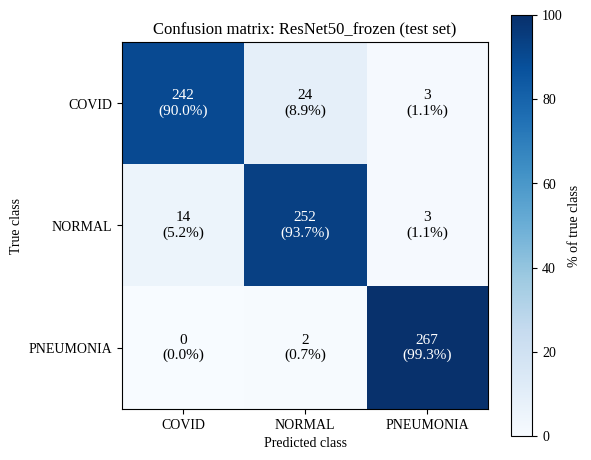

In [ ]:
from sklearn.metrics import confusion_matrix

# Confusion matrix for the validation-chosen model on the test set.
model_name = chosen                                   # e.g. 'ResNet50_finetuned'
probs = np.asarray(load_predictions(model_name, 'test'))
y_pred = probs.argmax(axis=1)                         # predicted class = highest probability

y_true = np.asarray(y_test)
if y_true.ndim > 1:                                   # convert one-hot labels to class numbers
    y_true = y_true.argmax(axis=1)

cm = confusion_matrix(y_true, y_pred, labels=range(len(class_names)))
row_pct = cm / cm.sum(axis=1, keepdims=True) * 100    # % of each TRUE class

with plt.rc_context({'font.family': 'serif',
                     'font.serif': ['Times New Roman', 'Liberation Serif', 'STIXGeneral']}):
    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(row_pct, cmap='Blues', vmin=0, vmax=100)

    # Each cell: count, with the % of that true class underneath.
    for i in range(len(class_names)):
        for j in range(len(class_names)):
            ax.text(j, i, f'{cm[i, j]}\n({row_pct[i, j]:.1f}%)', ha='center', va='center',
                    fontsize=11, color='white' if row_pct[i, j] > 55 else 'black')

    ax.set_xticks(range(len(class_names)), class_names)
    ax.set_yticks(range(len(class_names)), class_names)
    ax.set_xlabel('Predicted class')
    ax.set_ylabel('True class')
    ax.set_title(f'Confusion matrix: {model_name} (test set)')
    fig.colorbar(im, ax=ax, label='% of true class')
    plt.tight_layout()
    plt.show()

In [ ]:
# Stats for the selected model (highest validation macro-F1), including validation loss and accuracy.
row = comparison.loc[chosen].copy()
val = records[chosen]['metrics']['validation']
row['val_loss'] = val['loss']
row['val_accuracy'] = val['accuracy']

# Show validation stats first, then everything else in its original order.
first = ['val_rank', 'test_rank', 'val_loss', 'val_accuracy', 'val_macro_f1']
row = row[first + [c for c in row.index if c not in first]]

display(row.to_frame(chosen).style.format(precision=4))

,ResNet50_frozen
val_rank,1
test_rank,4
val_loss,0.1325
val_accuracy,0.9598
val_macro_f1,0.9595
test_loss,0.1432
test_accuracy,0.9430
test_macro_f1,0.9428
test_covid_recall,0.8996
test_macro_auc,0.9935


Below, GradCam displays the regions of the X-Rays that most influenced the models prediction.

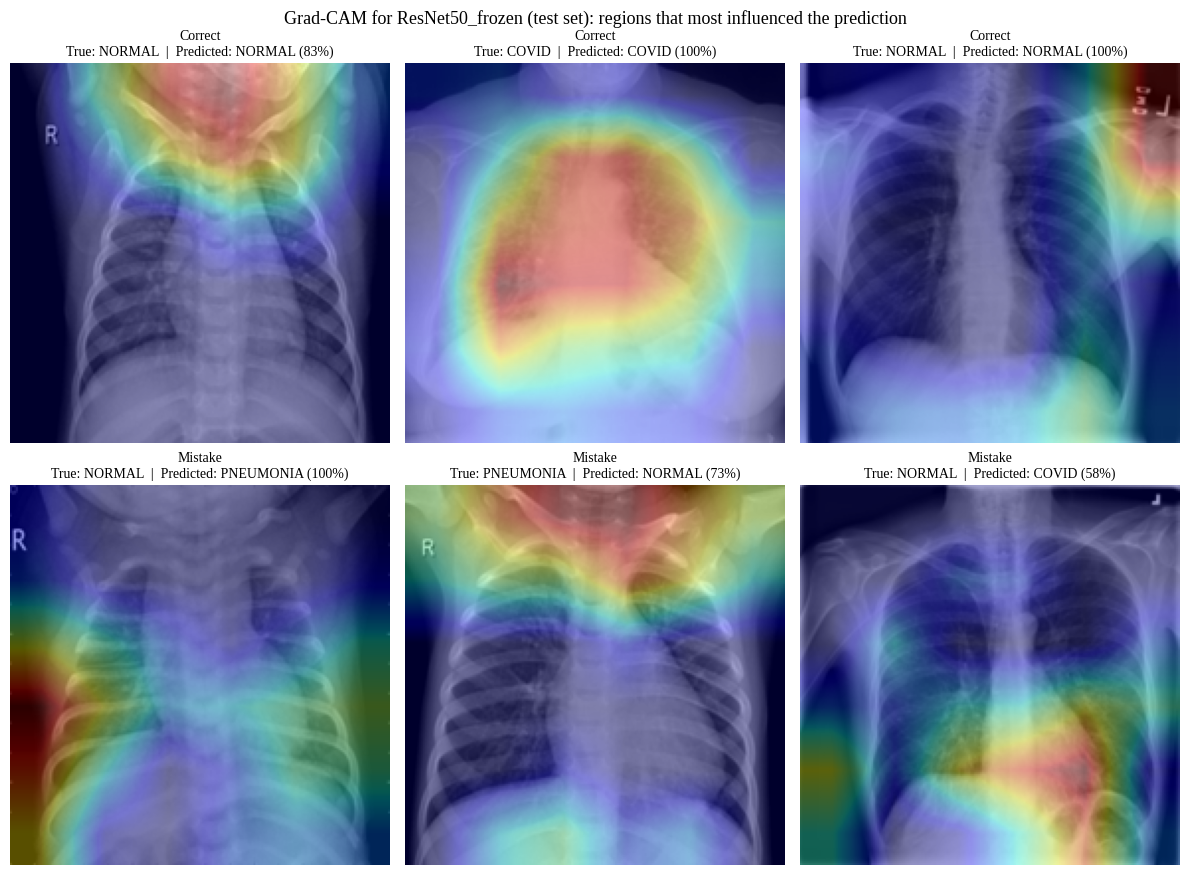

In [ ]:
import tensorflow as tf

# Grad-CAM: which image regions most influenced the model's predicted class.
gc_model = load_saved_model(chosen)                  # complete saved graph, e.g. ResNet50_frozen

def predict_with_features(images):
    """Run the model layer by layer, keeping the feature maps that enter the head."""
    features, out = None, images
    for layer in gc_model.layers:
        if isinstance(layer, keras.layers.InputLayer):
            continue
        if layer.name == 'classification_head':
            features = out                           # last convolutional feature maps
        out = layer(out, training=False)
    return features, out

def grad_cam(image, class_index):
    """Return a heatmap (values 0 to 1) the same height and width as the image."""
    x = tf.convert_to_tensor(image[None], dtype=tf.float32)
    with tf.GradientTape() as tape:
        features, probs = predict_with_features(x)
        tape.watch(features)
        score = probs[:, class_index]
    grads = tape.gradient(score, features)            # how each feature map affects the score
    weights = tf.reduce_mean(grads, axis=(1, 2))      # one importance weight per channel
    cam = tf.nn.relu(tf.reduce_sum(features * weights[:, None, None, :], axis=-1))[0]
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    cam = tf.image.resize(cam[..., None], image.shape[:2])[..., 0]
    return cam.numpy()

# Pick examples in the saved test order: 3 correct and 3 mistakes.
probs = np.asarray(load_predictions(chosen, 'test'))
y_pred = probs.argmax(axis=1)
y_true = np.asarray(y_test)
if y_true.ndim > 1:
    y_true = y_true.argmax(axis=1)
correct = np.where(y_pred == y_true)[0][:3]
wrong = np.where(y_pred != y_true)[0][:3]

with plt.rc_context({'font.family': 'serif',
                     'font.serif': ['Times New Roman', 'Liberation Serif', 'STIXGeneral']}):
    fig, axes = plt.subplots(2, 3, figsize=(12, 9))
    for row, (label, idx) in enumerate([('Correct', correct), ('Mistake', wrong)]):
        for ax, i in zip(axes[row], idx):
            heat = grad_cam(X_test[i], y_pred[i])
            ax.imshow(X_test[i])
            ax.imshow(heat, cmap='jet', alpha=0.35)
            ax.set_title(f'{label}\nTrue: {class_names[y_true[i]]}  |  '
                         f'Predicted: {class_names[y_pred[i]]} ({probs[i, y_pred[i]]:.0%})',
                         fontsize=10)
            ax.axis('off')
        for ax in axes[row][len(idx):]:
            ax.axis('off')                            # fewer than 3 examples: leave blank
    fig.suptitle(f'Grad-CAM for {chosen} (test set): regions that most influenced the prediction',
                 fontsize=13)
    plt.tight_layout(h_pad=2)
    plt.show()

**Transfer models:**
My top performing model was the ResNet50 frozen model. The model was selected using the validation macro-F1 score rather than the test score, so that the test set played no part in any decision and remains an unbiased estimate of how the chosen model would perform on new data. This model achieved a macro-f1 score of 0.96, indicating it performed strongly on classifying all three types of X-rays. The test score was only slightly lower, indicating that the model generalized well to unseen data.

<br>

The training of the model took 2.2 minutes, with a validation loss score of 0.13. The model ran ten epochs, and its top performing epoch was epoch 9. Because this model was not fine tuned, only the head was trained. The training and validation loss displayed above shows that the training loss score lowered each epoch for all ten epochs, while the validation loss score dropped for nine. This was also the case for the validation and training accuracy scores. Because the fitting stage included `EarlyStopping(monitor='val_loss', restore_best_weights=True)`, the weights learned at that 9th epoch were kept.

<br>

This model accurately labeled 94% of the X-rays in the testing dataset. It was strongest at labeling X-rays of pneumonia patients, having labeled approximately 99% correctly. It accurately labeled approximately 93% of normal X-rays and approximately 90% of the covid X-rays. The most common mistake the model made was labeling covid X-rays as normal X-rays. All transfer learning models performed strongly, with the lowest macro-F1 validation score achieved being 0.9378 (densenet).

**Baseline CNN:** <br>

The baseline CNN predicted COVID for every X-ray, giving an accuracy of 33%, the same as guessing, since the three classes were evenly split. As the loss plot above shows, validation loss was lowest at epoch 1 and never improved, even though training loss kept falling. Because early stopping restores the weights with the lowest validation loss, the model kept its epoch-1 weights, discarding what it learned in later epochs.
Keeping the epoch-1 weights left the baseline CNN barely trained. It still carried a weak signal (macro AUC 0.63, above the 0.5 of random guessing), but not enough to change its answers, so it predicted COVID for every X-ray. A likely contributor is batch normalization: after only one epoch, the running statistics it uses at prediction time had not settled, which skewed every image's output toward the same class.

In [ ]:
# How many test images the baseline CNN assigned to each class.
class_names = list(class_names)                     # class names, in probability-column order
probs = np.asarray(load_predictions('BaselineCNN', 'test'))
y_pred = probs.argmax(axis=1)                       # predicted class = highest probability

y_true = np.asarray(y_test)
if y_true.ndim > 1:                                 # convert one-hot labels to class numbers
    y_true = y_true.argmax(axis=1)

n = len(class_names)
counts = pd.DataFrame({
    'predicted': np.bincount(y_pred, minlength=n),  # includes classes predicted 0 times
    'actual': np.bincount(y_true, minlength=n),
}, index=class_names)
counts['predicted_%'] = (counts['predicted'] / counts['predicted'].sum() * 100).round(1)
counts['actual_%'] = (counts['actual'] / counts['actual'].sum() * 100).round(1)
counts.loc['Total'] = counts.sum(numeric_only=True)

display(counts)

,predicted,actual,predicted_%,actual_%
COVID,807.0,269.0,100.0,33.3
NORMAL,0.0,269.0,0.0,33.3
PNEUMONIA,0.0,269.0,0.0,33.3
Total,807.0,807.0,100.0,99.9


Differences between labeling in training and prediction modes:

In [ ]:
# Compare the baseline's predictions in prediction mode vs training mode.
def has_batchnorm(layer):
    if isinstance(layer, keras.layers.BatchNormalization):
        return True
    return any(has_batchnorm(l) for l in getattr(layer, 'layers', []))

src = Path(RESTORE_FROM) if RESTORED else RUN_DIR
keras.backend.clear_session()
bl, _, _, _ = build_baseline()
bl.load_weights(src / 'BaselineCNN.weights.h5')
print('Baseline has batch normalization:', has_batchnorm(bl))

x = X_train[:512]
y = np.asarray(y_train)[:512].argmax(axis=1)
for training_mode in [False, True]:
    p = np.concatenate([keras.ops.convert_to_numpy(bl(x[i:i + 64], training=training_mode))
                        for i in range(0, len(x), 64)])
    pred = p.argmax(axis=1)
    counts = {class_names[k]: int((pred == k).sum()) for k in range(len(class_names))}
    label = 'training mode  ' if training_mode else 'prediction mode'
    print(f'{label}: accuracy {np.mean(pred == y):.3f}  predictions {counts}')

Baseline has batch normalization: True
prediction mode: accuracy 0.334  predictions {'COVID': 512, 'NORMAL': 0, 'PNEUMONIA': 0}
training mode  : accuracy 0.729  predictions {'COVID': 178, 'NORMAL': 158, 'PNEUMONIA': 176}


**Conclusion**:

These models should not be used for clinical use. There are only three classes that the model classifies X-rays, "normal", "Covid", or "Pneumonia", but there are many possible lung conditions that do not fall into these three categories (Example: tuberculosis). It also is not able to determine if an X-ray indicates that an individual has multiple conditions (single label VS. multilabel classification). The model only sees what is in the image, but it does not have any data on an individual's symptoms. While the model can classify between these three classes, it is unable to describe the severity of a condition. The top model would be a tool possibly for triaging, in particular individuals who are suspected of having pneumonia, rather than for any type of official diagnosis.

## References

- Instructor's Project 2 notebook and shared COVID-19 Radiography dataset.
- Chowdhury et al. (2020), [Can AI help in screening Viral and COVID-19 pneumonia?](https://arxiv.org/abs/2003.13145).
- TensorFlow, [Transfer learning and fine-tuning](https://www.tensorflow.org/guide/keras/transfer_learning).
- Keras, [Applications](https://keras.io/api/applications/) and [EfficientNet models](https://keras.io/api/applications/efficientnet/efficientnet_models/).